# 4.0.5-Re-do embedding of all cohort

**Inés Sentís**

Date of execution

In [1]:
Sys.Date()

[1] "2026-02-03"

## Libraries

In [2]:
suppressMessages(suppressWarnings({
library(Seurat)
library(Signac)
library(tidyverse)
library(scater) 
library(scran)
library(harmony)
library(here)
library(glue)
}))

## Parameters

In [3]:
#here::dr_here(show_reason = TRUE)
source(here("utils/bin.R"))
source(here("utils/paths.R"))
source(here("AVGUSTINOVA_02_to_30/utils/style.R"))
source(here("AVGUSTINOVA_02_to_30/utils/variables.R"))
set.seed(0)

## Load Data

In [4]:
integrated_obj <- readRDS(here(glue("{int}/{robj_dir}/4.0.4-intgr_clustering.rds")))

In [5]:
integrated_obj <- DietSeurat(integrated_obj,
                           counts = TRUE,
                           data = TRUE,
                           assays = c("ATAC_unified", "RNA"),
                           dimreducs = NULL,
                           graphs = NULL)

#### Remove ribosomal

In [6]:
DefaultAssay(integrated_obj) <- "RNA"
ribosomal_genes <- grep("^RP[SL]", rownames(integrated_obj[["RNA"]]), value = TRUE)
integrated_obj[["RNA"]] <- subset(integrated_obj[["RNA"]], 
                                  features = setdiff(rownames(integrated_obj[["RNA"]]), ribosomal_genes))

In [7]:
list_objects <- SplitObject(integrated_obj, split.by = "subproj")

In [8]:
mt_genes <- grep("^MT-", rownames(integrated_obj[["RNA"]]), value = TRUE)

In [9]:
genes_dmf <- c("XACT", "HTR2C","XIST", "DDX3Y","USP9Y","NLGN4Y", "KDM5D", "EIF1AY", "UBA1")
genes_out <- c(genes_dmf, top_c, mt_genes) 

In [10]:
find_hvgs <-  function(obj) {
    
    batch <- unique(obj$subproj)
    
    # remove genes from matrix before modulating variance and mean
    DefaultAssay(obj) <- "RNA"
    df_meta <- obj@meta.data
    counts <- obj[['RNA']]@counts
    counts <- counts[-(which(rownames(counts) %in% genes_out)),]
    obj2 <- CreateSeuratObject(counts = counts, meta.data = df_meta)
    
    # normalize again
    obj2 <- obj2 %>% 
            NormalizeData(
                normalization.method = "LogNormalize",
                scale.factor = 1e4) 
    
    # compute the variance and mean of the log-expression values 
    sce <- as.SingleCellExperiment(obj2)
    gene_var <- modelGeneVar(sce)
    
    tops <- gene_var %>% 
        as.data.frame() %>% 
        arrange(desc(total)) %>% 
        head(n=20)

    plt <- gene_var %>% 
      as.data.frame() %>% 
      ggplot(aes(mean, total)) +
      geom_point() +
      geom_line(aes(y = tech), colour = "dodgerblue", size = 1) +
      labs(x = "Mean of log-expression", y = "Variance of log-expression")+
      geom_text(data=tops, aes(mean,total,label=rownames(tops))) + 
      ggtitle(batch) + 
      theme(plot.title = element_text(hjust = 0.5, size = 12, face = "bold"))

    hvgs <- getTopHVGs(gene_var,fdr.threshold = 0.05)
    return(list(plot = plt, hvgs_pat = hvgs))
}

In [11]:
modelling <- lapply(list_objects, find_hvgs)

Warning message:
“Using `size` aesthetic for lines was deprecated in ggplot2 3.4.0.
ℹ Please use `linewidth` instead.”


In [12]:
list_plots <- lapply(modelling, function(el) {
    el$plot
})

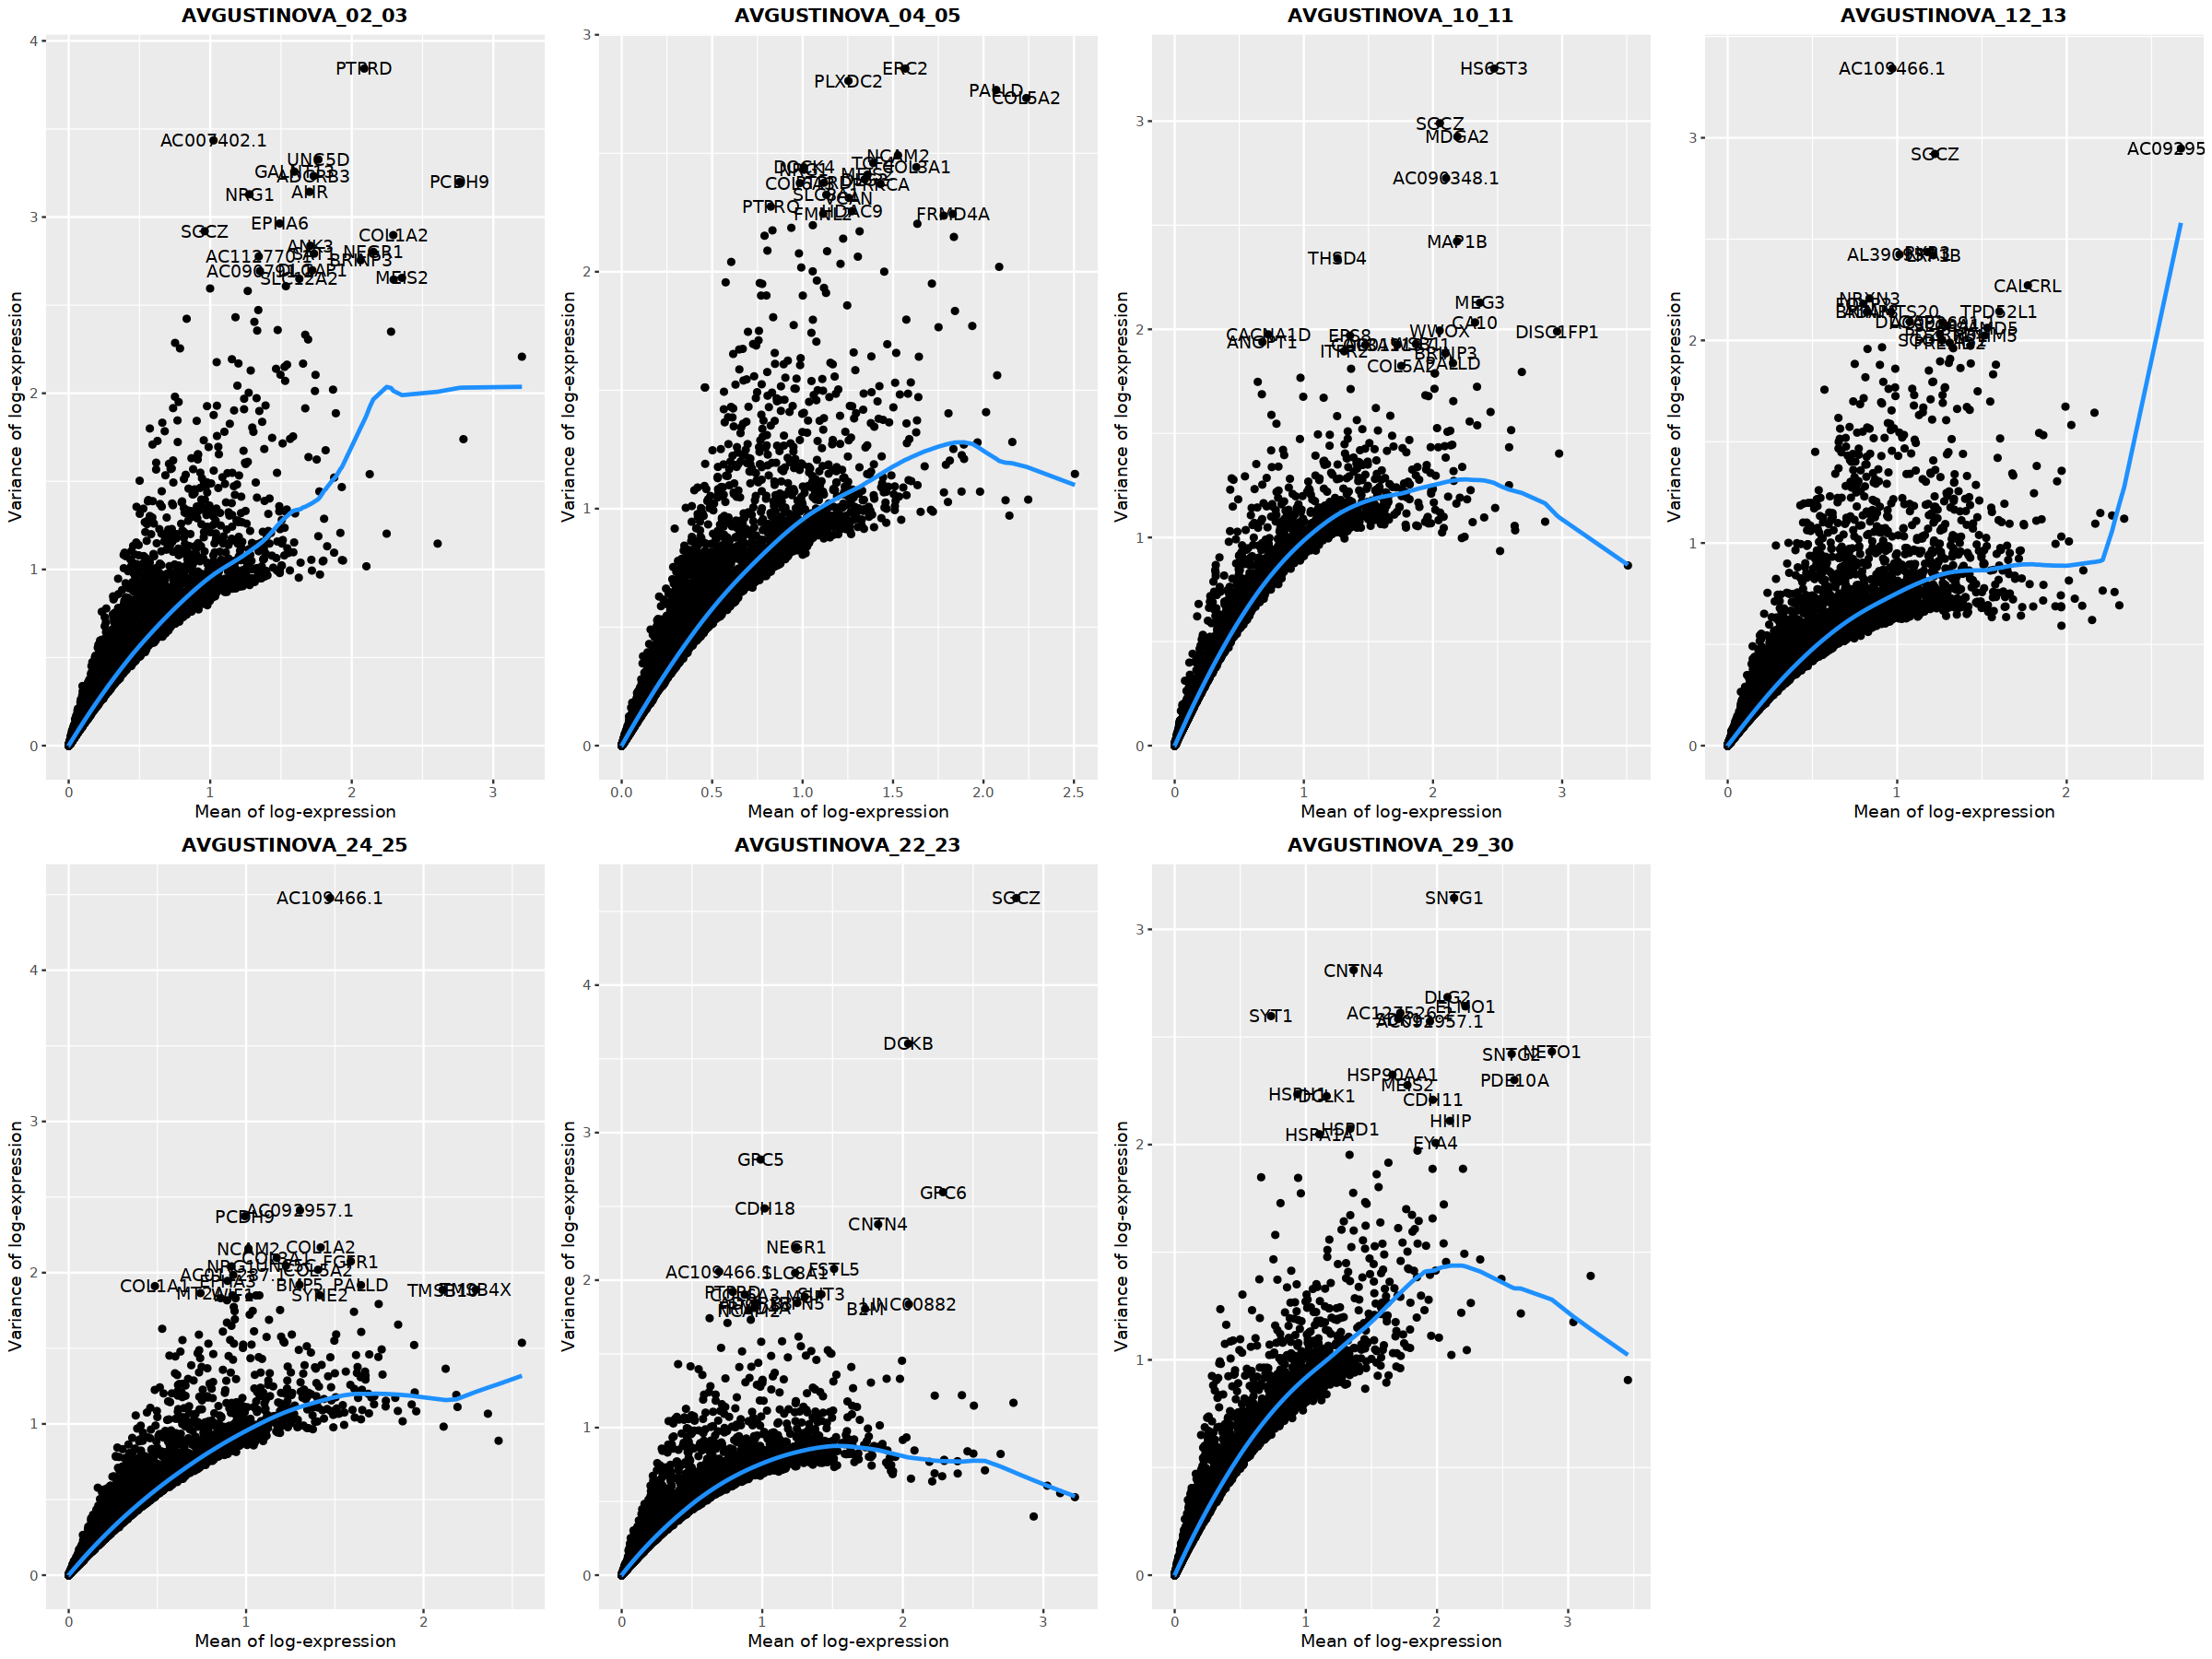

In [13]:
options(repr.plot.width = 20, repr.plot.height = 15)
cowplot::plot_grid(plotlist = list_plots,
                   align = "hv",
                   axis = "trbl",
                   ncol=4)

In [14]:
list_hvg <- lapply(modelling, function(el) {
    hvg <- el$hvgs_pat
    print(length(hvg))
    hvg
})

[1] 1348
[1] 1995
[1] 4167
[1] 1810
[1] 6193
[1] 4941
[1] 2910


In [15]:
hvg_common <- find_perc(list_hvg, perc = 2/7)
length(hvg_common)

[1] 5605

#### Highly variable peaks 

Find top peaks per patient in from the consensus unified peak calls and use a cut off of 10% which means 
to include features with >10 total counts in the set of VariableFeatures

In [16]:
list_hvp <- lapply(list_objects, function(obj) {
  DefaultAssay(obj) <- "ATAC_unified"
  hvp <-VariableFeatures(FindTopFeatures(obj[["ATAC_unified"]], min.cutoff = 10))
  return(hvp)
})

In [17]:
hvp_common <- Reduce(intersect, list_hvp)
length(hvp_common)

[1] 158964

## ATAC unified

In [18]:
DefaultAssay(integrated_obj) <- "ATAC_unified"

VariableFeatures(integrated_obj) <- hvp_common
integrated_obj <- RunTFIDF(integrated_obj)
integrated_obj <- RunSVD(integrated_obj,features=hvp_common, reduction.name = "lsi.common")

Performing TF-IDF normalization

Running SVD

Scaling cell embeddings



In [19]:
dim(Embeddings(integrated_obj, reduction = "lsi.common"))

[1] 102171     50

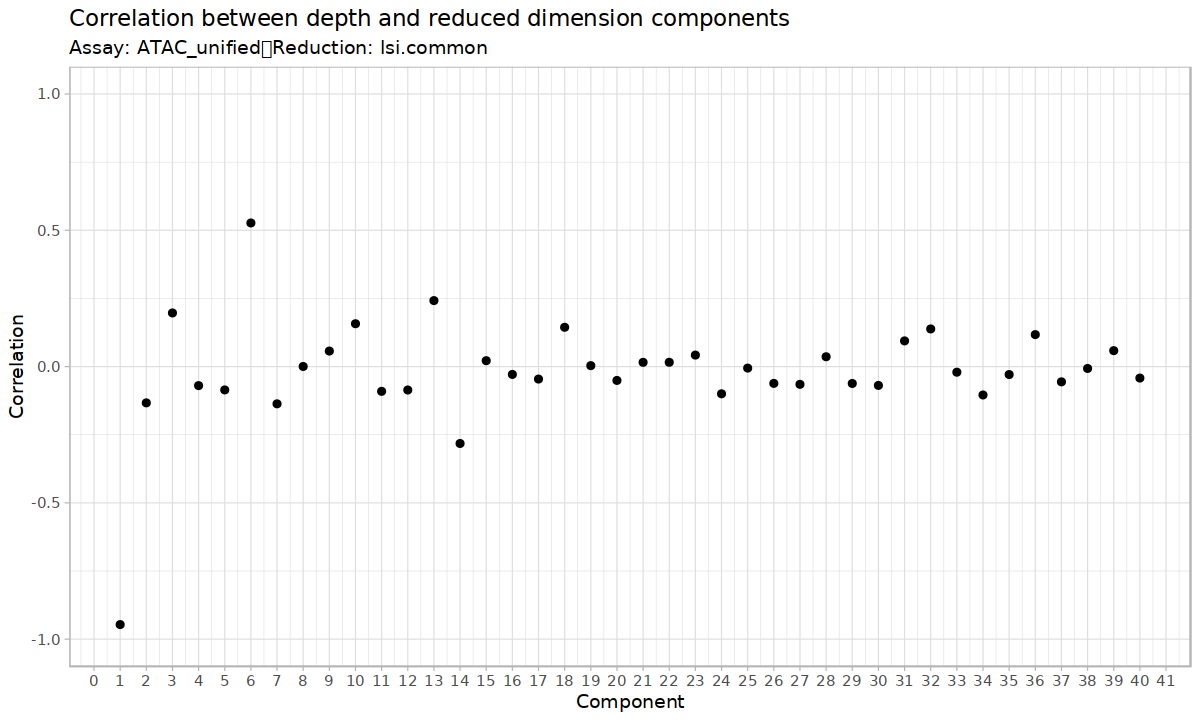

In [20]:
options(repr.plot.width = 10, repr.plot.height = 6)
DepthCor(integrated_obj, reduction = "lsi.common", n=40)

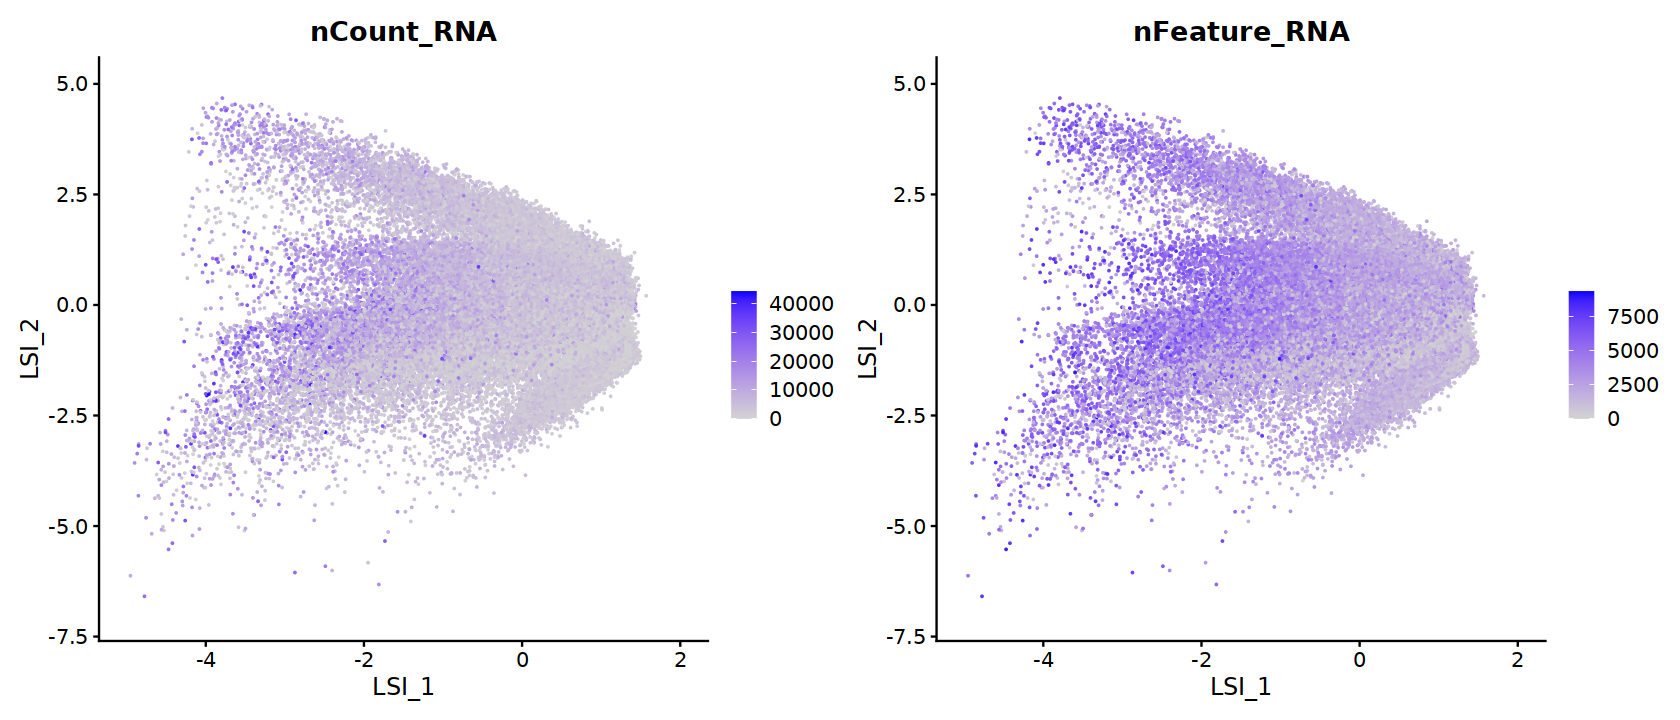

In [21]:
options(repr.plot.width = 14, repr.plot.height = 6)
FeaturePlot(integrated_obj, reduction = "lsi.common", 
            features = c("nCount_RNA", "nFeature_RNA"),raster=FALSE)

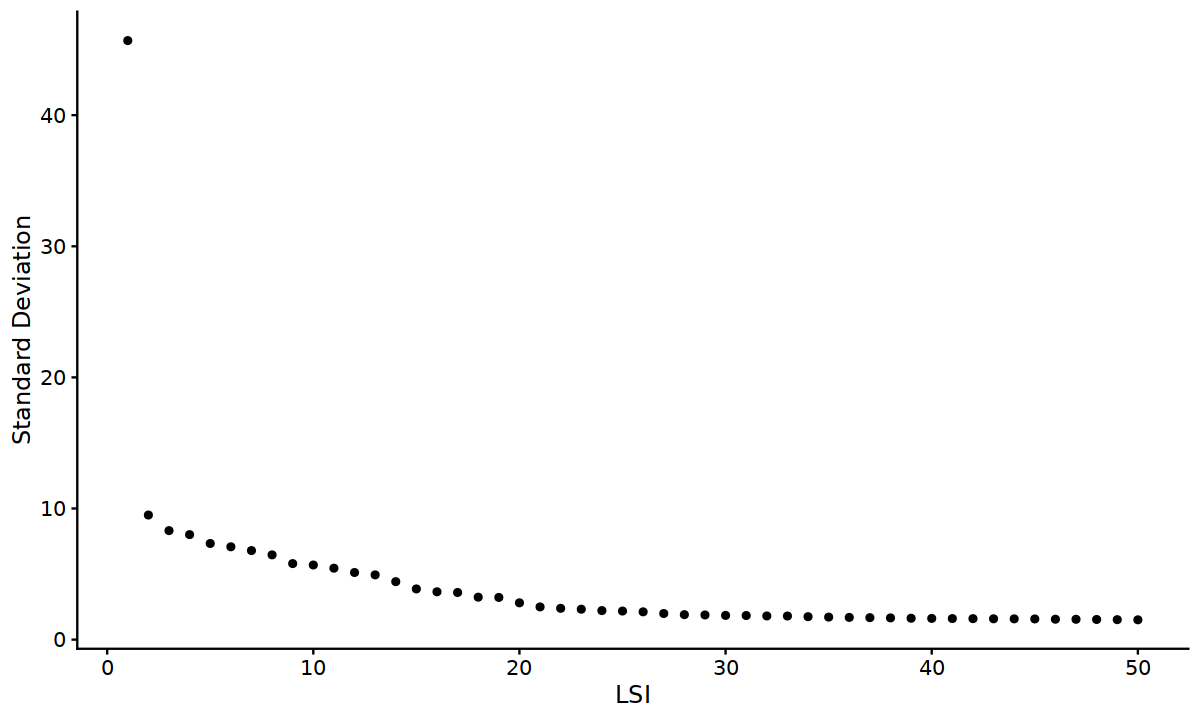

In [22]:
options(repr.plot.width = 10, repr.plot.height = 6)
ElbowPlot(integrated_obj,reduction="lsi.common", ndims=50)

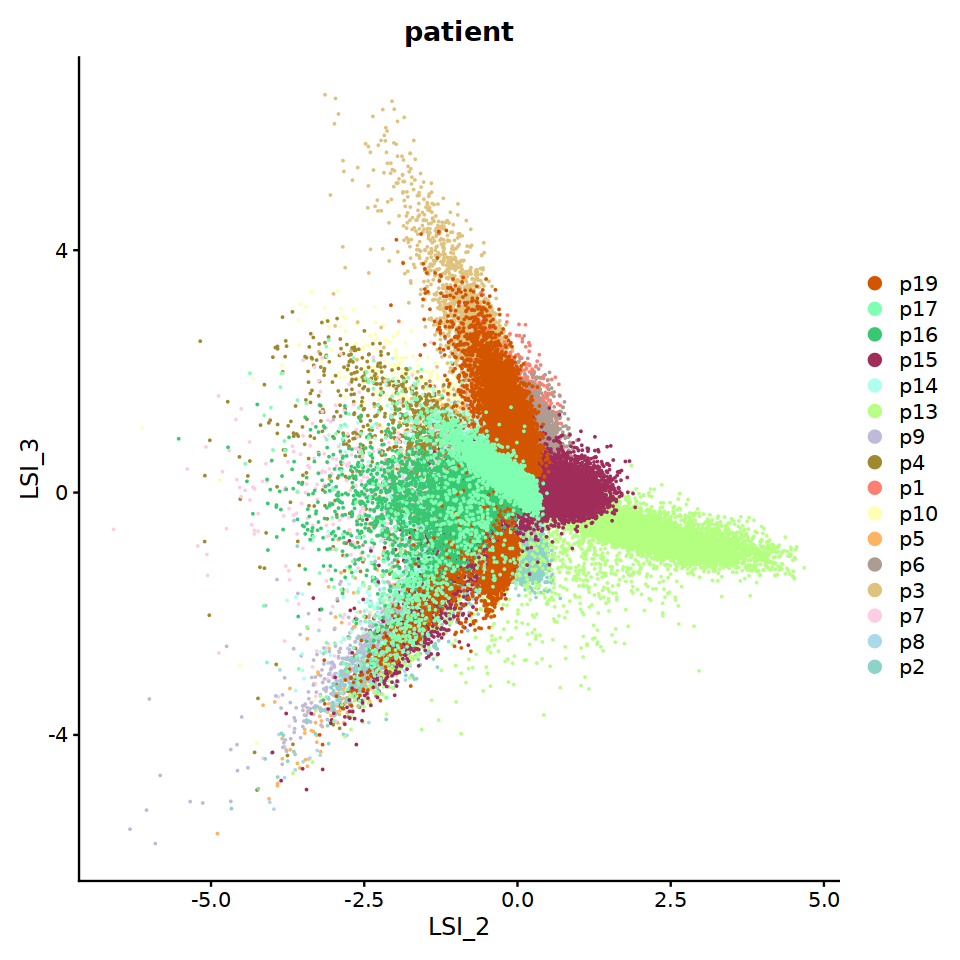

In [23]:
options(repr.plot.width = 8, repr.plot.height = 8)
DimPlot(integrated_obj, reduction = "lsi.common", group.by = "patient", 
        dims=c(2,3), cols=colors_patients,raster=FALSE)

## RNA

In [24]:
DefaultAssay(integrated_obj) <- "RNA"

VariableFeatures(integrated_obj) <- hvg_common
 
integrated_obj <- integrated_obj %>% 
  NormalizeData(normalization.method = "LogNormalize",
                scale.factor = 1e4) %>% 
  ScaleData(features= hvg_common) %>% 
  RunPCA(features= hvg_common) 

Centering and scaling data matrix

PC_ 1 
Positive:  TTC28, MIR100HG, MSRB3, MEIS2, MEOX2, NR2F1-AS1, ARHGAP28, PALLD, BMP5, GULP1 
	   GPC6, DNM3, ADAMTS6, AC092957.1, AC011246.1, NAALADL2, BRINP3, NOVA1, GRIP1, COL5A2 
	   PPFIBP1, CALCRL, PPP1R9A, AL008633.1, LGR4, ERVMER61-1, HHIP, FGFR1, ABCA5, NEGR1 
Negative:  DOCK4, PTPRC, LRMDA, DOCK2, DOCK8, ZEB2, SAMSN1, ARHGAP15, CHST11, SRGN 
	   FYB1, PLXDC2, FMN1, TBXAS1, DPYD, SLC9A9, MS4A6A, SLCO2B1, APBB1IP, ARHGAP26 
	   LNCAROD, CTSB, NPL, LCP2, AOAH, TLR2, MGAT4A, KYNU, FAM49A, GPRIN3 
PC_ 2 
Positive:  TMSB4X, BMP5, MEOX2, DCN, HSP90AA1, B2M, ARHGAP28, AL390957.1, WIF1, PDGFC 
	   AC011246.1, COL5A2, S100A10, OLFM3, LURAP1L, HGF, HSPE1, MPPED2, S100A6, ABCA8 
	   LINC01915, COL19A1, PEG3, COL3A1, C5orf17, CD74, DNM3, HLA-DRA, AC011586.2, ADAMTS6 
Negative:  CLIC6, EPB41L4A, SAMD5, AL033504.1, MARK1, PDLIM5, TPD52L1, ENPP2, LINC00472, PDZRN3 
	   LMX1A, TYR, CDH2, ASXL3, RAI14, EFEMP1, TMEM108, RYR3, SLCO3A1, BCL2 
	   PTPRM, AGBL4

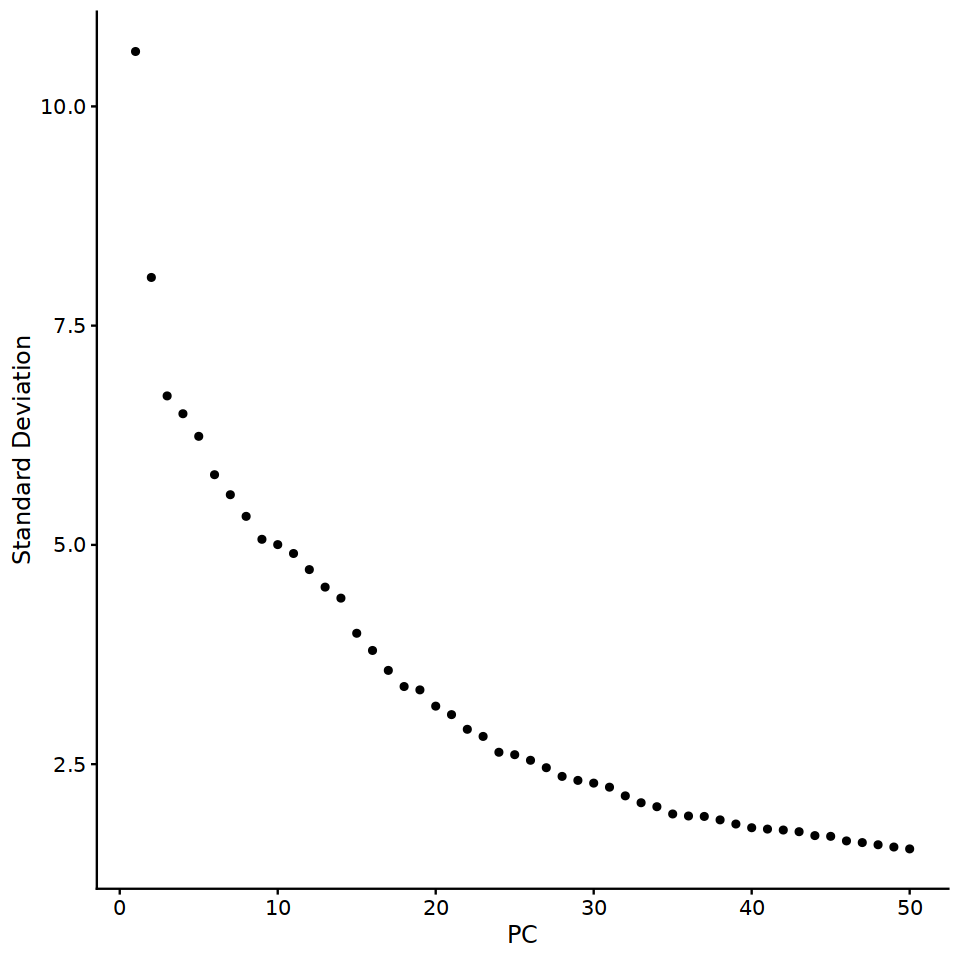

In [25]:
ElbowPlot(integrated_obj, ndims=50)

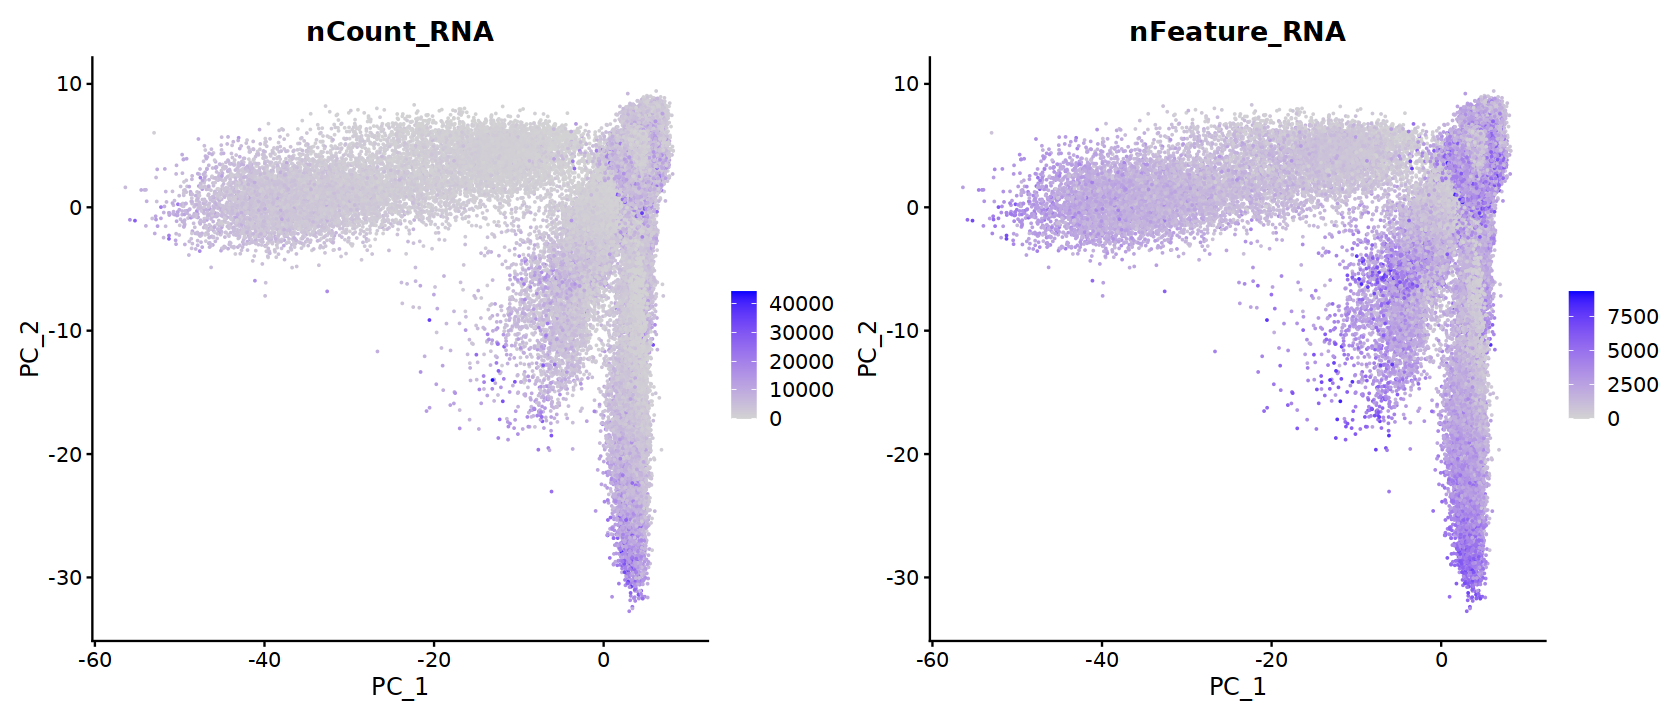

In [26]:
options(repr.plot.width = 14, repr.plot.height = 6)
FeaturePlot(integrated_obj, reduction = "pca", features = c("nCount_RNA", "nFeature_RNA"),raster=FALSE)

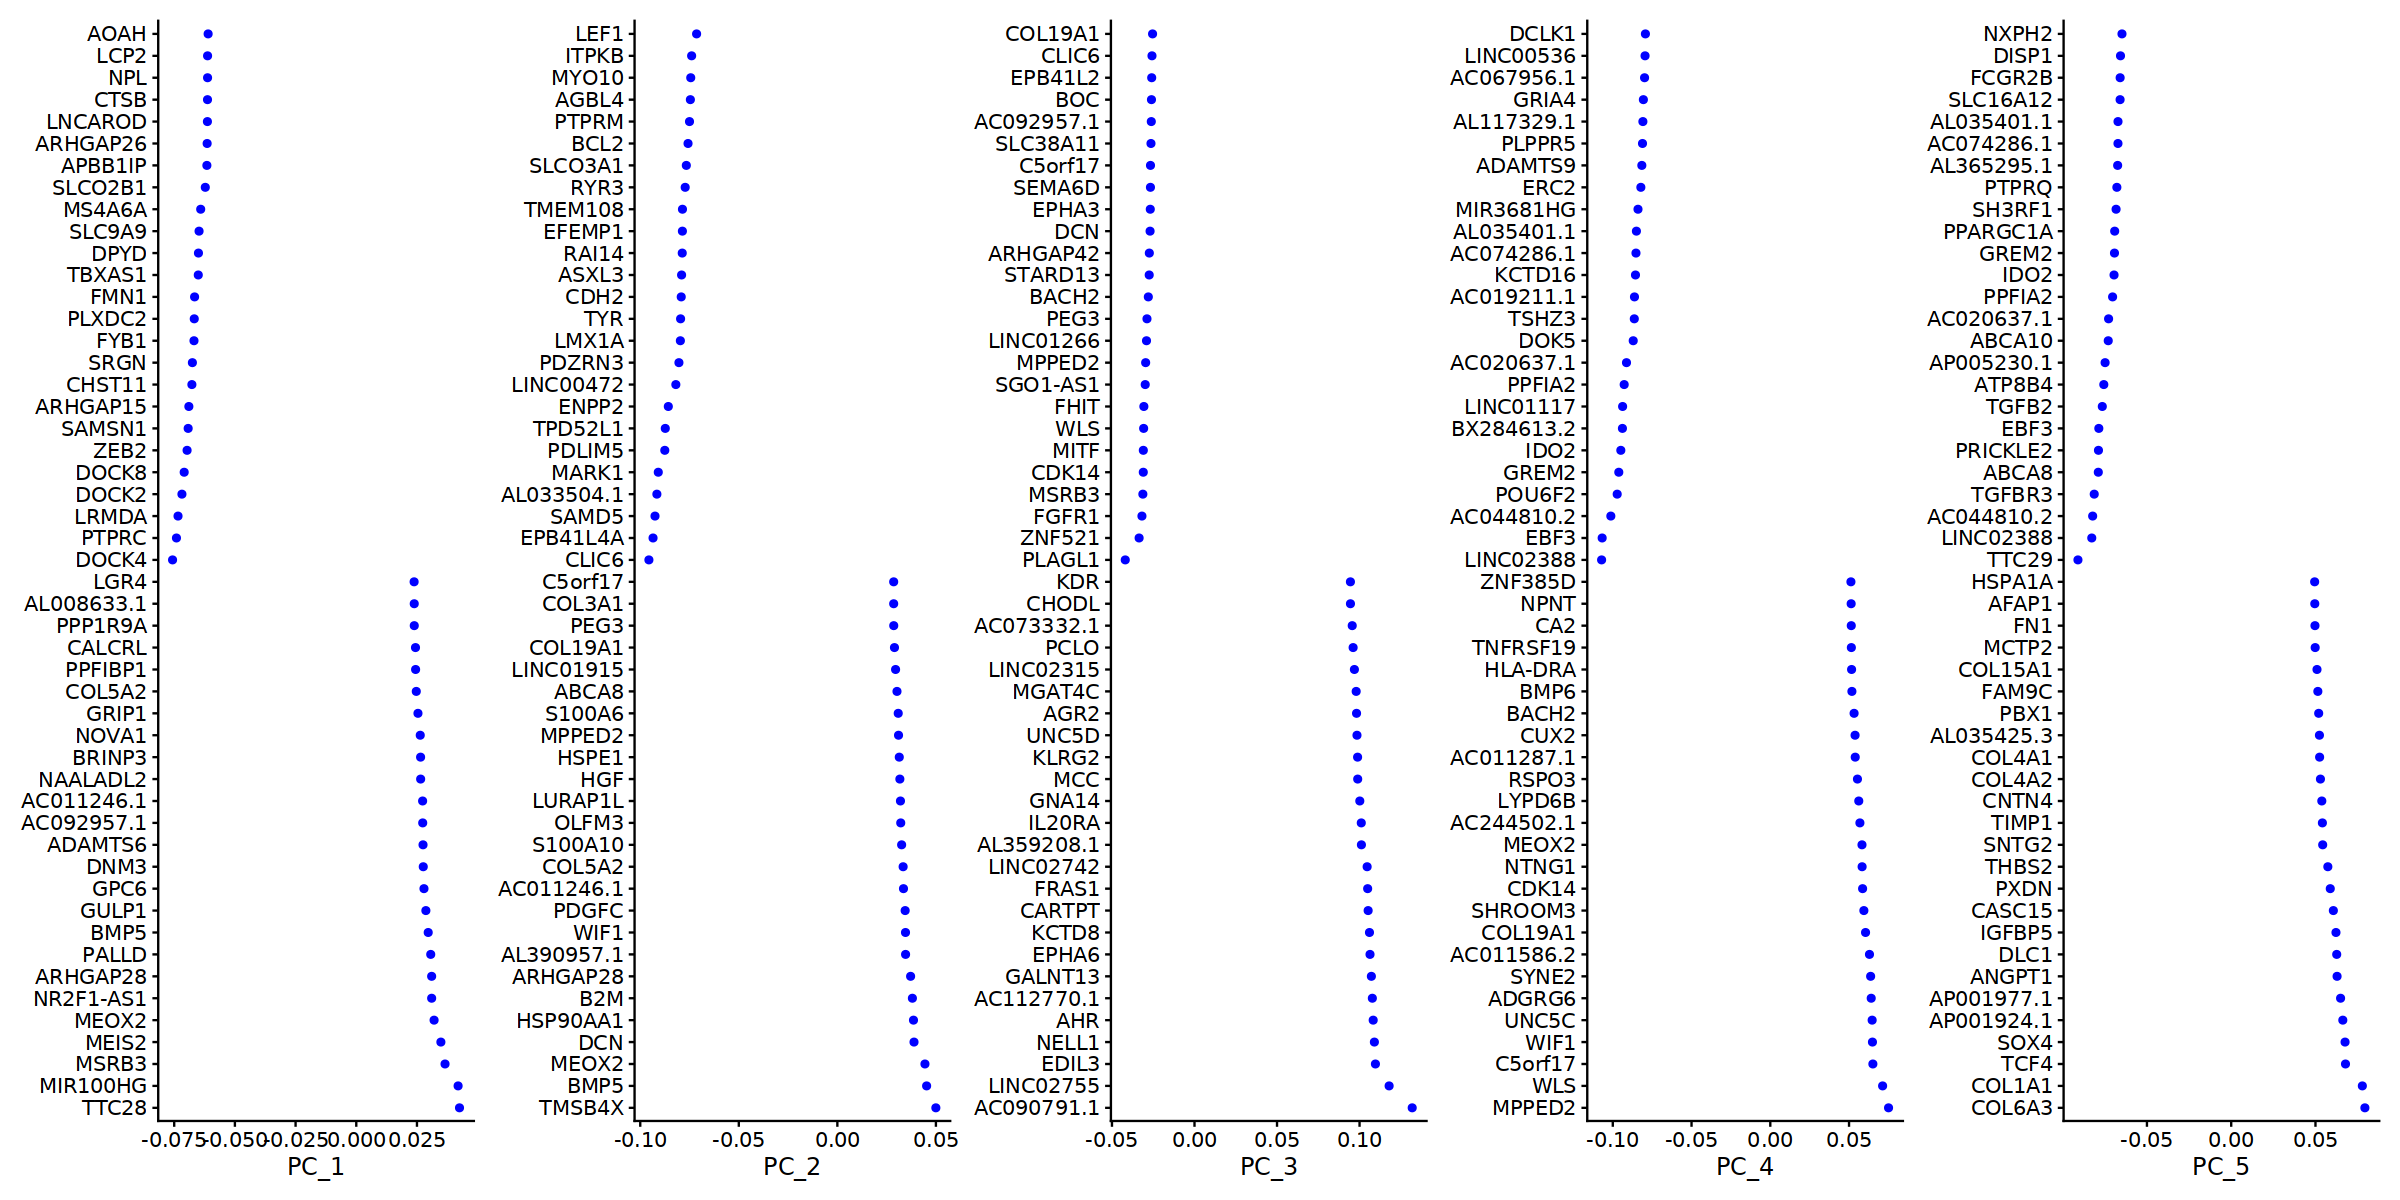

In [27]:
options(repr.plot.width = 20, repr.plot.height = 10)
VizDimLoadings(integrated_obj, dims = 1:5, reduction = "pca", ncol=5, nfeatures=50, balanced=TRUE)

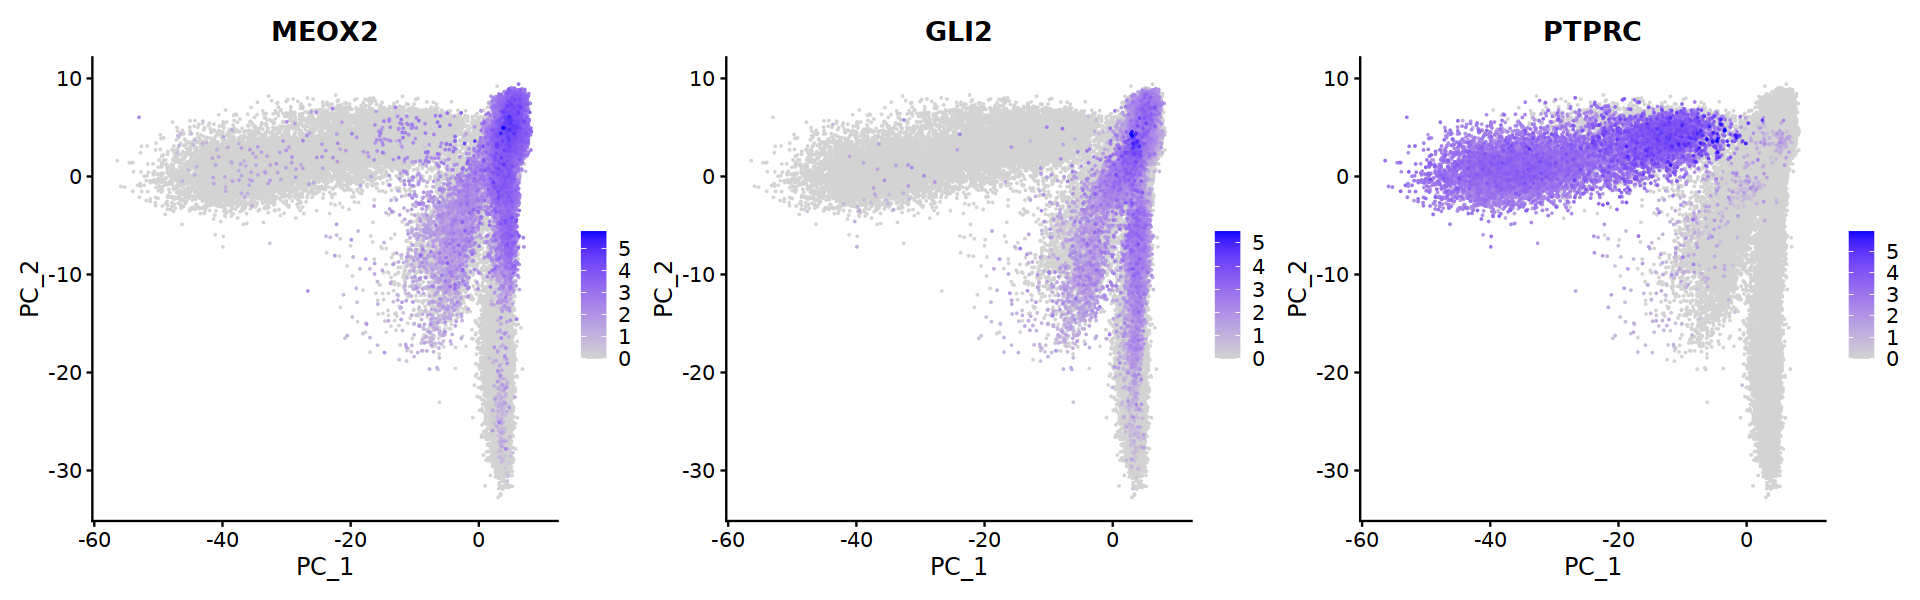

In [28]:
options(repr.plot.width = 16, repr.plot.height = 5)
FeaturePlot(integrated_obj, reduction = "pca", 
            features = c("MEOX2", "GLI2", "PTPRC"), 
            order=T, ncol=3,raster=FALSE)

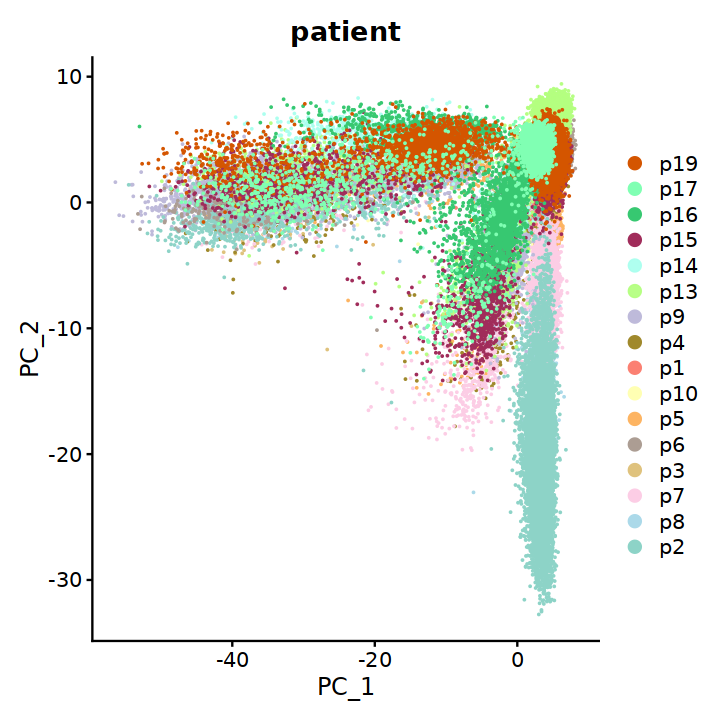

In [29]:
options(repr.plot.width = 6, repr.plot.height = 6)
DimPlot(integrated_obj, reduction = "pca", group.by = "patient", 
        cols= colors_patients, raster=FALSE)

In [30]:
rna_comp = 1:40
atac_comp = 2:20

### Joint (WNN)

In [31]:
integrated_obj <- FindMultiModalNeighbors(
 integrated_obj,
 reduction.list = list("pca", "lsi.common"),
 dims.list = list(rna_comp, atac_comp)
)

Calculating cell-specific modality weights

Finding 20 nearest neighbors for each modality.

Calculating kernel bandwidths

Finding multimodal neighbors

Constructing multimodal KNN graph

Constructing multimodal SNN graph



In [32]:
integrated_obj <- RunUMAP(
   integrated_obj,
   nn.name = "weighted.nn",
   reduction.name = "wnn.umap",
   reduction.key = "wnnUMAP_")

Warning message:
“The default method for RunUMAP has changed from calling Python UMAP via reticulate to the R-native UWOT using the cosine metric
To use Python UMAP via reticulate, set umap.method to 'umap-learn' and metric to 'correlation'
This message will be shown once per session”
14:10:44 UMAP embedding parameters a = 0.9922 b = 1.112

14:10:45 Commencing smooth kNN distance calibration using 1 thread
 with target n_neighbors = 20

14:10:46 28 smooth knn distance failures

14:10:49 Initializing from normalized Laplacian + noise (using irlba)

14:10:59 Commencing optimization for 200 epochs, with 3421308 positive edges

14:13:25 Optimization finished



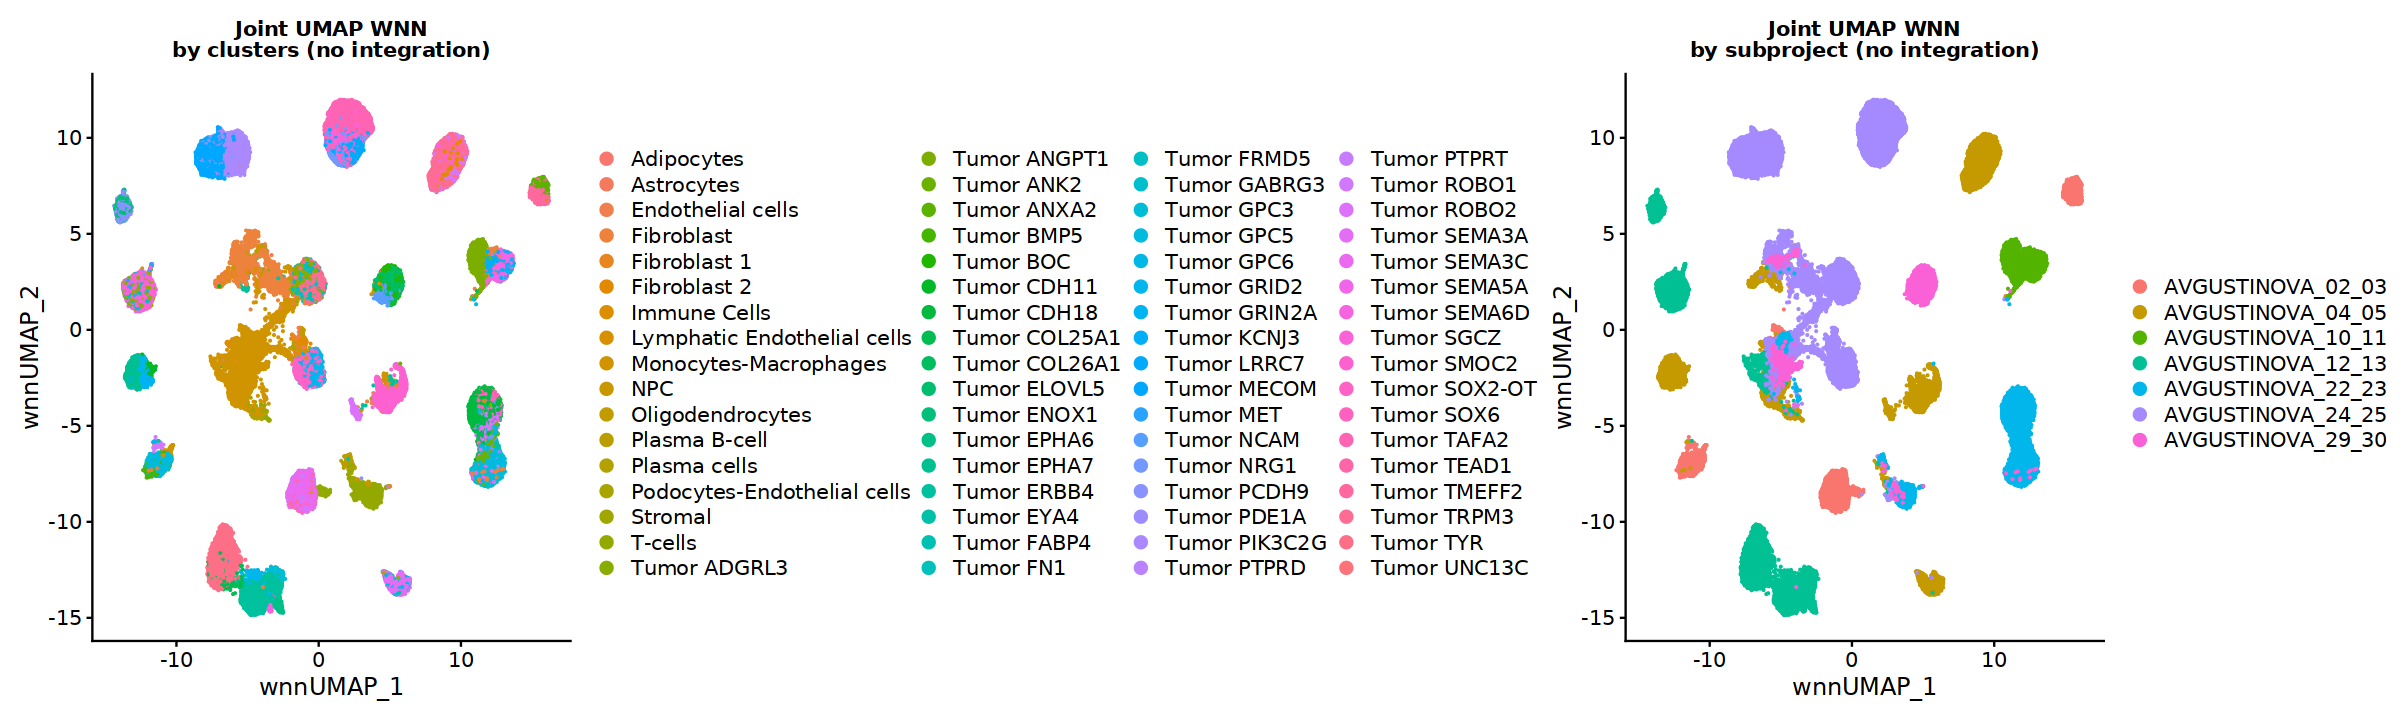

In [33]:
options(repr.plot.width = 20, repr.plot.height = 6)
p1 <- DimPlot(
  integrated_obj,
   reduction = "wnn.umap",
   group.by = "clusters_donor",
   pt.size = 0.1,
   raster=FALSE
) + ggtitle('Joint UMAP WNN\nby clusters (no integration)') + 
    theme(plot.title = element_text(hjust = 0.5, size = 12, face = "bold"))

p2 <- DimPlot(
  integrated_obj,
   reduction = "wnn.umap",
   group.by = "subproj",
   pt.size = 0.1,
   raster=FALSE
) + ggtitle('Joint UMAP WNN\nby subproject (no integration)') + 
    theme(plot.title = element_text(hjust = 0.5, size = 12, face = "bold"))

patchwork::wrap_plots(list(p1,p2), ncol=2)

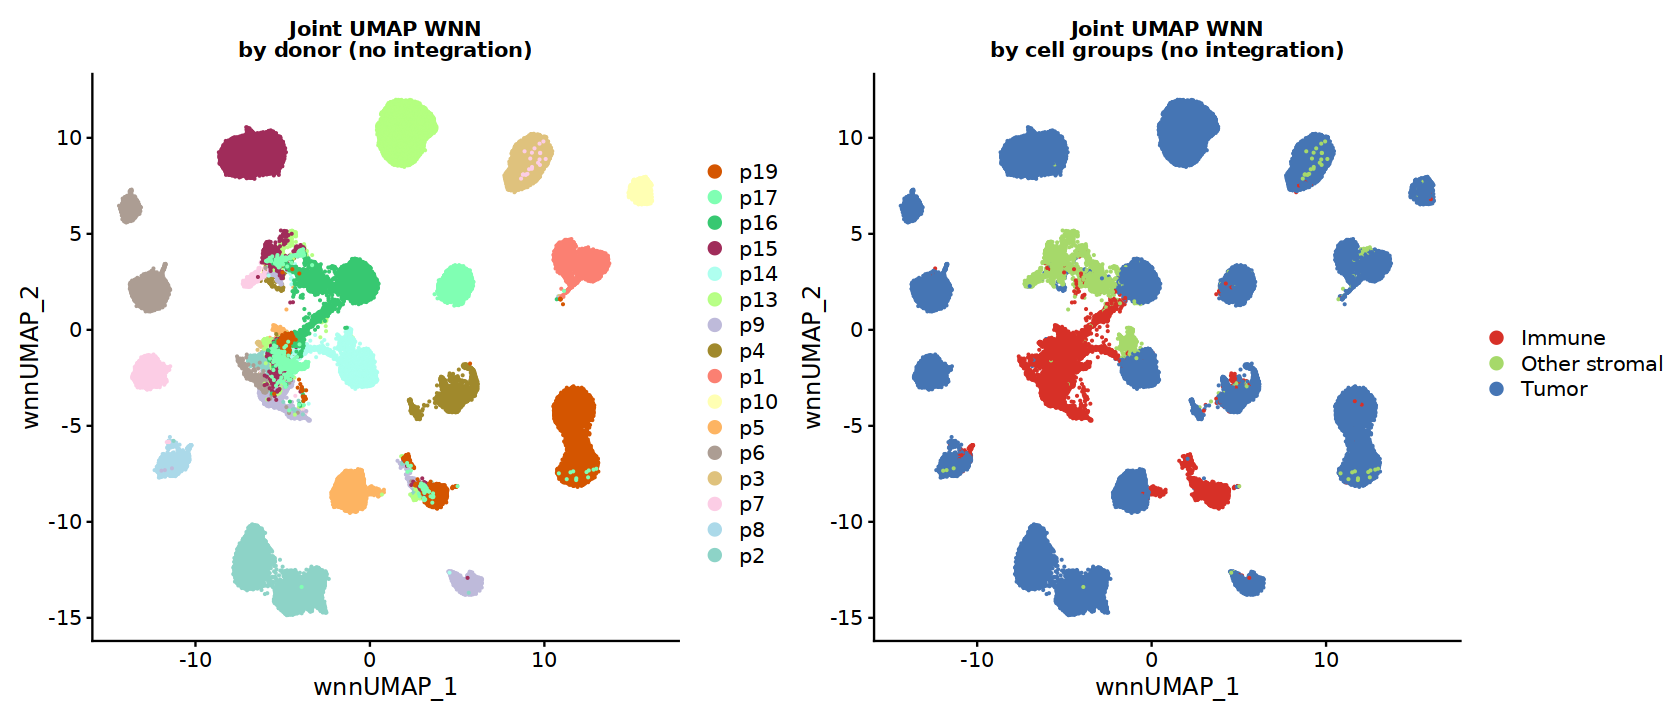

In [34]:
options(repr.plot.width = 14, repr.plot.height = 6)
p1 <-DimPlot(
  integrated_obj,
   reduction = "wnn.umap",
   group.by = "patient",
   cols= colors_patients, 
   pt.size = 0.1,
   raster=FALSE
) + ggtitle('Joint UMAP WNN\nby donor (no integration)') + 
    theme(plot.title = element_text(hjust = 0.5, size = 12, face = "bold")) 

p2 <- DimPlot(
  integrated_obj,
   reduction = "wnn.umap",
   group.by = "cell_groups",
   pt.size = 0.1,
   cols=colors_cellg,
   raster=FALSE
) + ggtitle('Joint UMAP WNN\nby cell groups (no integration)') + 
    theme(plot.title = element_text(hjust = 0.5, size = 12, face = "bold"))

patchwork::wrap_plots(list(p1,p2), ncol=2)

In [35]:
p4 <- FeaturePlot(
  integrated_obj,
   reduction = "wnn.umap",
   features = "PTPRC",
   pt.size = 0.1,
   order = T,
   raster=FALSE
) + ggtitle('Joint UMAP WNN\n CD45') + 
    theme(plot.title = element_text(hjust = 0.5, size = 12, face = "bold")) 

p5 <- FeaturePlot(
  integrated_obj,
   reduction = "wnn.umap",
   features = "CD3E",
   pt.size = 0.1,
   order = T,
   raster=FALSE
) + ggtitle('Joint UMAP WNN\n CD3E') + 
    theme(plot.title = element_text(hjust = 0.5, size = 12, face = "bold")) 

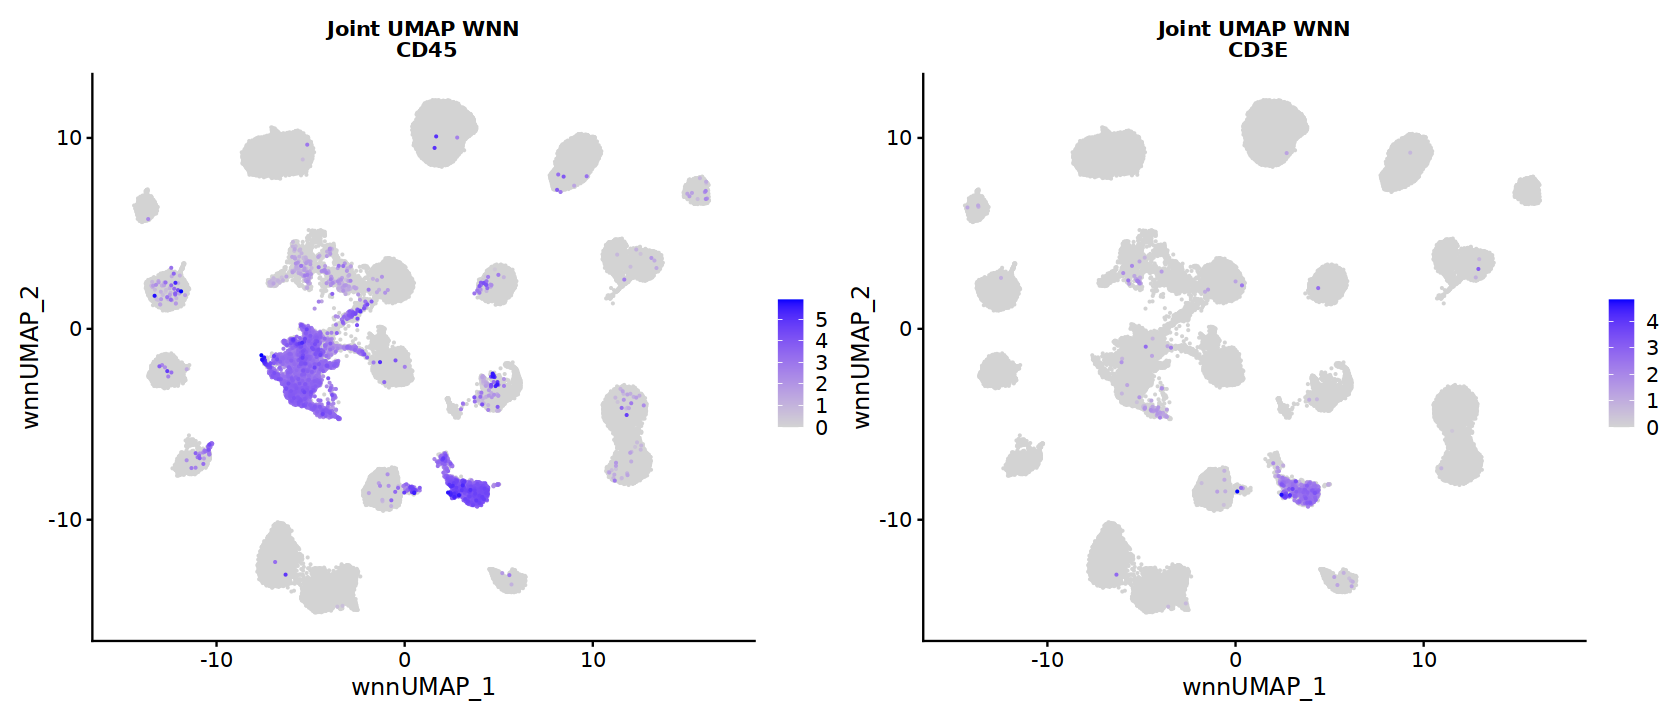

In [36]:
options(repr.plot.width = 14, repr.plot.height = 6)
patchwork::wrap_plots(list(p4,p5), ncol=2)

## Integration with Harmony

### RNA

In [37]:
# make a copy of the PCA reduction
integrated_obj@reductions$pca_filt <- integrated_obj@reductions$pca

# Filter to the desired number of components according to elbow
integrated_obj@reductions$pca_filt@cell.embeddings <- integrated_obj@reductions$pca_filt@cell.embeddings[, rna_comp]

integrated_obj@reductions$pca_filt@feature.loadings <- integrated_obj@reductions$pca_filt@feature.loadings[, rna_comp]


integrated_obj <- RunHarmony(
  object = integrated_obj,
  reduction = "pca_filt",
  dims = rna_comp,
  group.by.vars = c("patient"),
  assay.use = "RNA",
  project.dim = T,
  return.model = T,
  max_iter = 15,
  reduction.save = "harmony_pca"
)

Transposing data matrix

Harmony 1/15

Harmony 2/15

Harmony converged after 2 iterations

Warning message:
“Invalid name supplied, making object name syntactically valid. New object name is Seurat..ProjectDim.RNA.harmony_pca; see ?make.names for more details on syntax validity”


#### PCA regression

In [38]:
df_info <- read_csv(here("utils/info_samples.csv"),show_col_types = FALSE)
df_clinical <- df_info[df_info$modality == "multiome",]
df_clinical <- df_clinical[,c("patient", "subproject", "quality", "location", "age_simple", 
                              "methylome", "alteration_status", "treatment_status")]

In [39]:
df_tmp <- integrated_obj@meta.data %>%
    rownames_to_column("barcodes") %>%
    left_join(df_clinical, by = "patient") %>%
    column_to_rownames("barcodes")

In [40]:
#integrated_obj@meta.data <- df_tmp
copy_obj <- integrated_obj
copy_obj@meta.data <- df_tmp

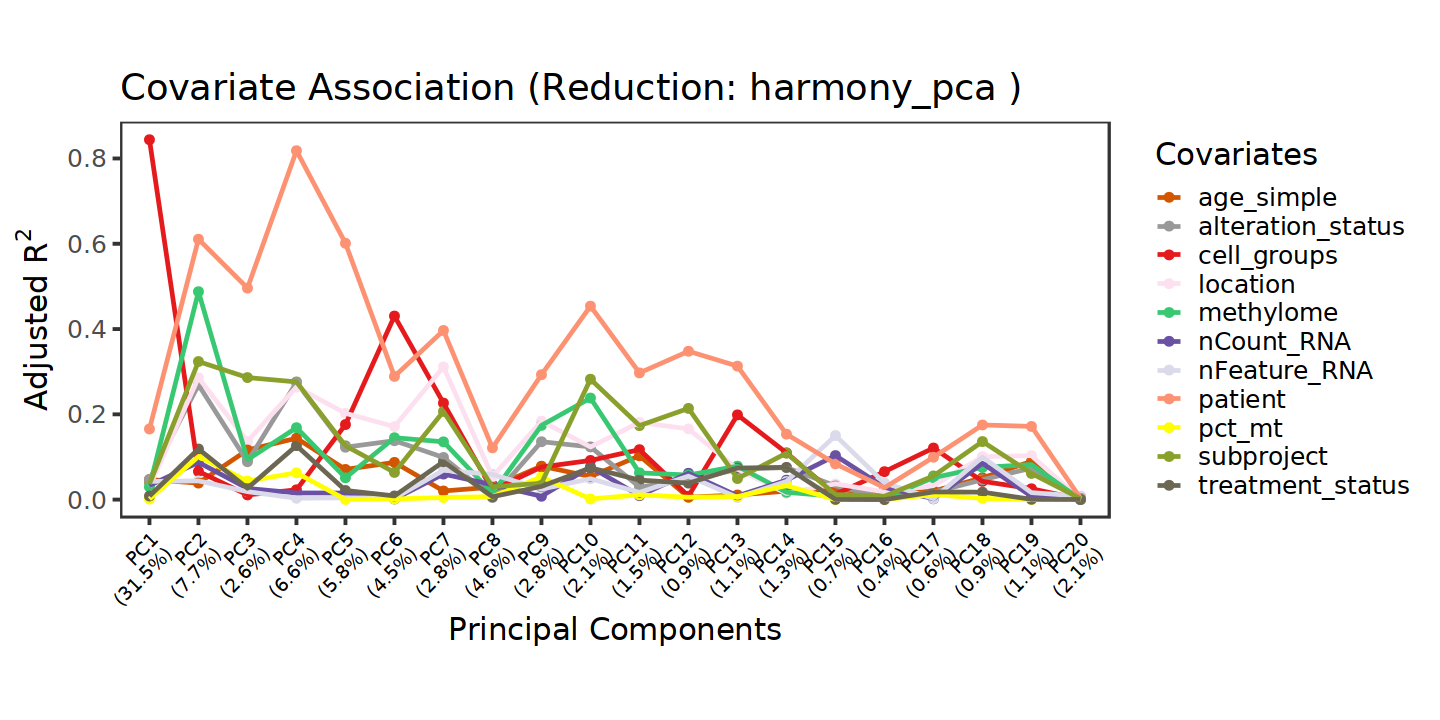

In [41]:
options(repr.plot.width = 12, repr.plot.height = 6)

pcr_plot <- .plotPcr(
   obj = copy_obj, 
   var_list = covariates, 
   color_palette = cov_colors, 
   reduction = "harmony_pca",
   comp = 1:20
 )
pcr_plot

In [42]:
remove(copy_obj)
remove(df_clinical)

In [43]:
ggsave(plot = pcr_plot, width = 12, height = 6, dpi = 300, 
       file = here::here(glue::glue("{int}/{plt_dir}/4.0.5-PCR_plot.svg")))

In [44]:
integrated_obj <- RunUMAP(
  integrated_obj,
  dims = rna_comp,
  reduction = "harmony_pca",
  reduction.name = "umap.rna.harmony",
  reduction.key = "RNAhar_",
  assay = "RNA")

14:15:03 UMAP embedding parameters a = 0.9922 b = 1.112

14:15:03 Read 102171 rows and found 40 numeric columns

14:15:03 Using Annoy for neighbor search, n_neighbors = 30

14:15:03 Building Annoy index with metric = cosine, n_trees = 50

0%   10   20   30   40   50   60   70   80   90   100%

[----|----|----|----|----|----|----|----|----|----|

*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
|

14:15:14 Writing NN index file to temp file /scratch_tmp/53625861/RtmpxpwnoJ/file2f99ea86748d

14:15:14 Searching Annoy index using 1 thread, search_k = 3000

14:15:54 Annoy recall = 100%

14:15:56 Commencing smooth kNN distance calibration using 1 thread
 with target n_neighbors = 30

14:15:57 24 smooth knn distance failures

14:16:01 Initializing from normalized Laplacian + noise (using irlba)

14:16:11 Commencing optimization for 200 epochs, with 4769094 positive edges

14:18:18 Optimization finished



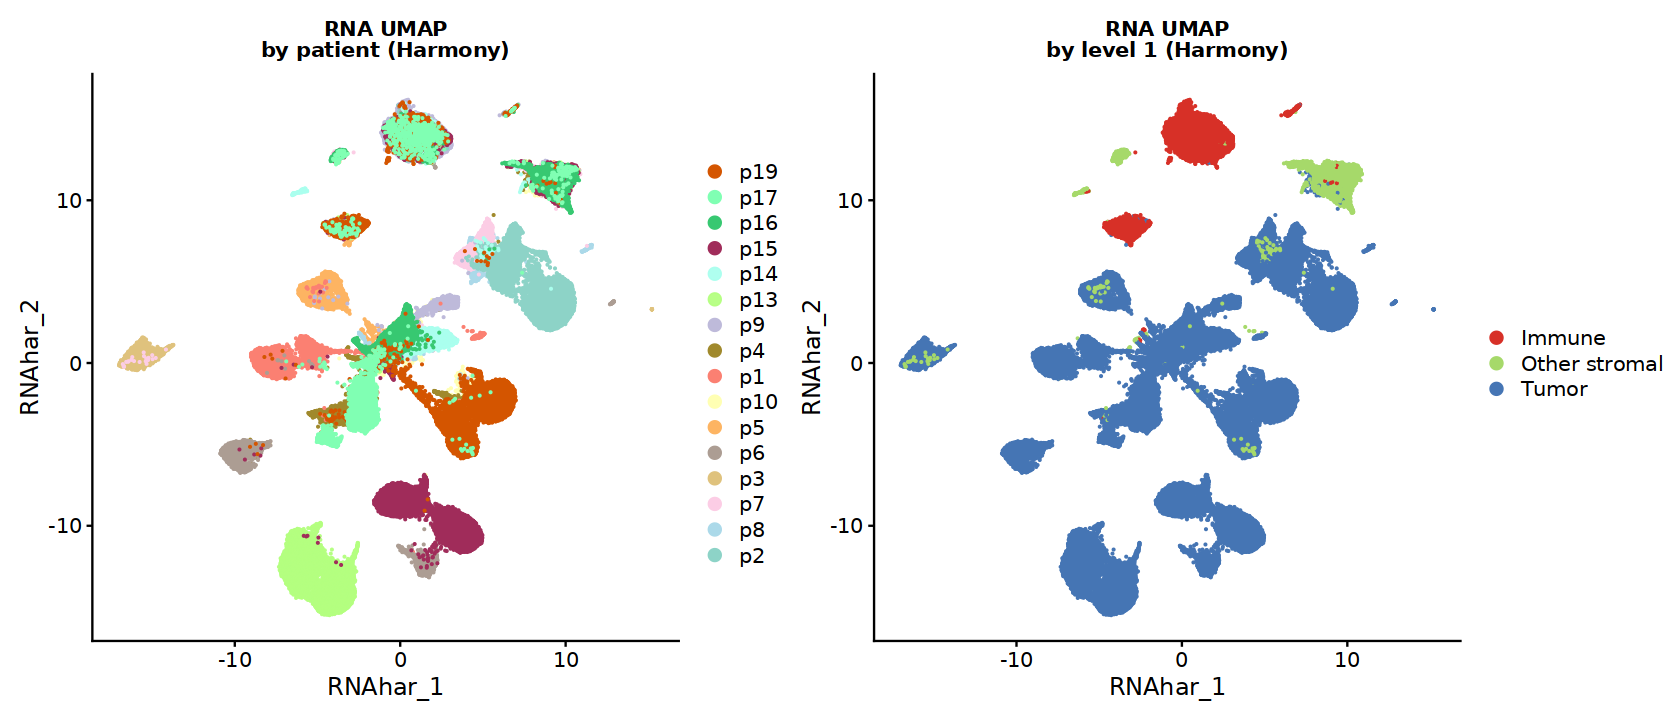

In [45]:
options(repr.plot.width = 14, repr.plot.height = 6)
p1 <- DimPlot(
  integrated_obj,
   reduction = "umap.rna.harmony",
   group.by = "patient",
   cols= colors_patients,
   pt.size = 0.1,
   raster=FALSE
) + ggtitle('RNA UMAP\nby patient (Harmony)') + 
    theme(plot.title = element_text(hjust = 0.5, size = 12, face = "bold")) 

p2 <- DimPlot(
  integrated_obj,
   reduction = "umap.rna.harmony",
   group.by = "cell_groups",
   pt.size = 0.1,
   cols=colors_cellg,
   raster=FALSE
) + ggtitle('RNA UMAP\nby level 1 (Harmony)') + 
    theme(plot.title = element_text(hjust = 0.5, size = 12, face = "bold"))

patchwork::wrap_plots(list(p1,p2), ncol=2)

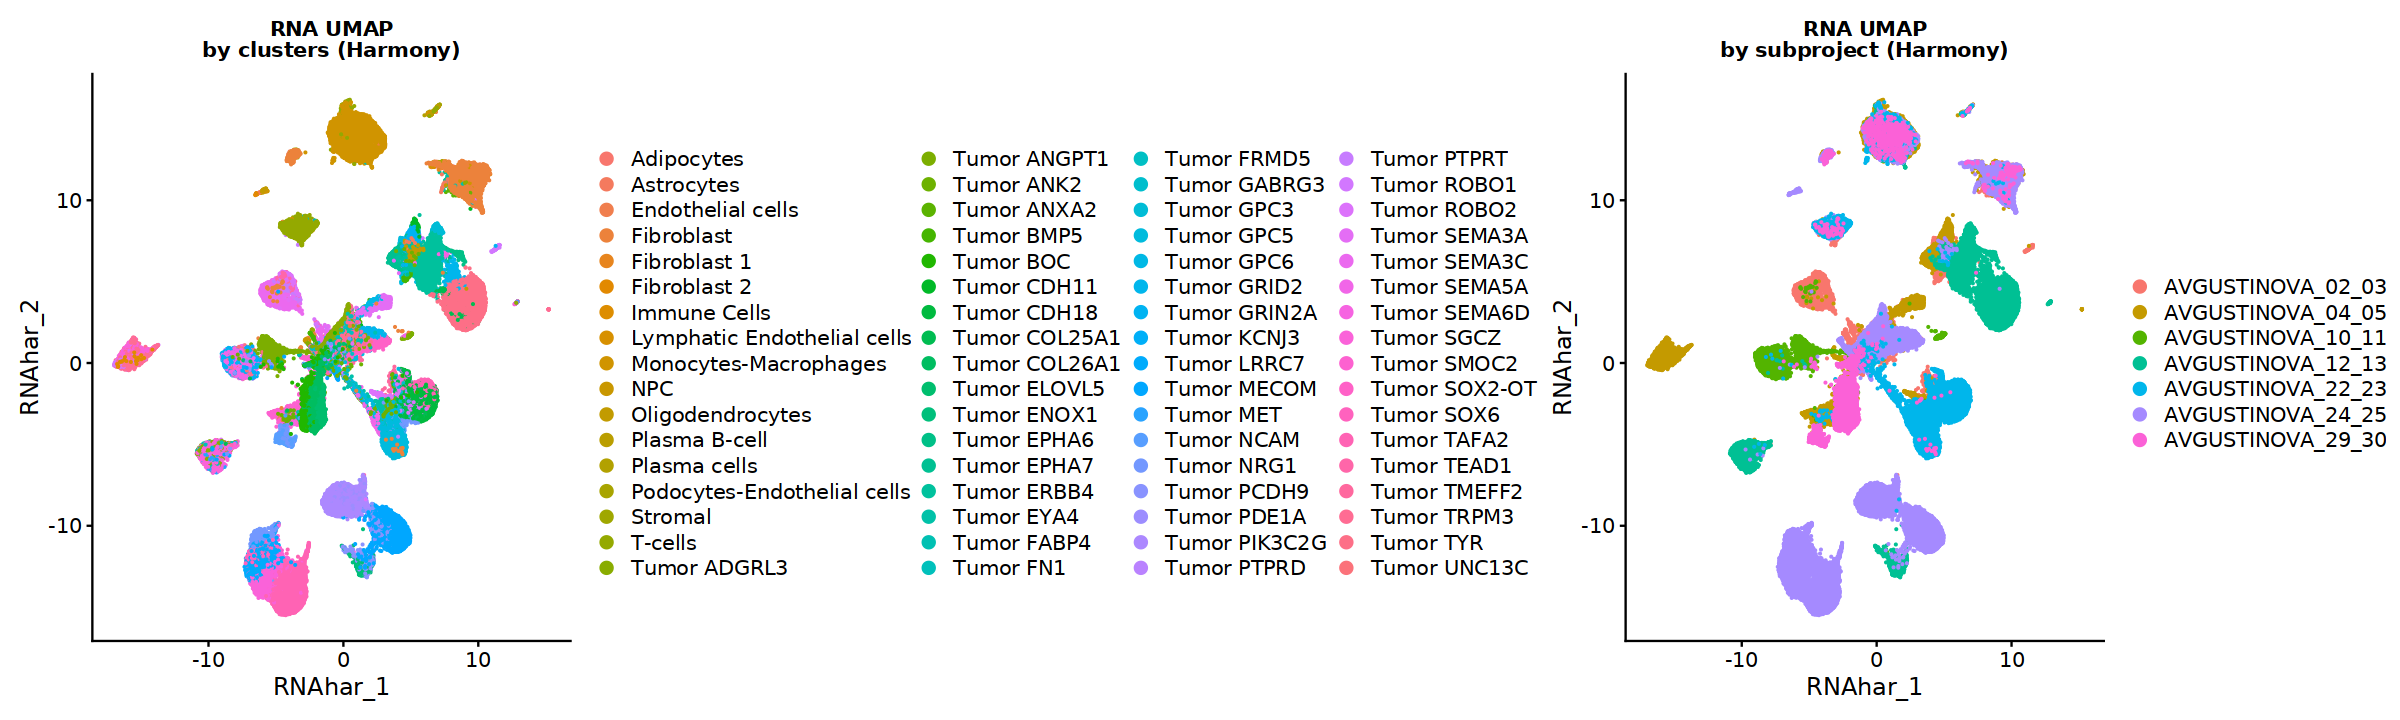

In [46]:
options(repr.plot.width = 20, repr.plot.height = 6)
p1 <- DimPlot(
  integrated_obj,
   reduction = "umap.rna.harmony",
   group.by = "clusters_donor",
   pt.size = 0.1,
   raster=FALSE
) + ggtitle('RNA UMAP\nby clusters (Harmony)') + 
    theme(plot.title = element_text(hjust = 0.5, size = 12, face = "bold"))

p2 <- DimPlot(
  integrated_obj,
   reduction = "umap.rna.harmony",
   group.by = "subproj",
   pt.size = 0.1,
   raster=FALSE
) + ggtitle('RNA UMAP\nby subproject (Harmony)') + 
    theme(plot.title = element_text(hjust = 0.5, size = 12, face = "bold"))

patchwork::wrap_plots(list(p1,p2), ncol=2)

In [47]:
p4 <- FeaturePlot(
  integrated_obj,
   reduction = "umap.rna.harmony",
   features = "PTPRC",
   pt.size = 0.1,
   order = T,
   raster=FALSE
) + ggtitle('RNA UMAP\n CD45') + 
    theme(plot.title = element_text(hjust = 0.5, size = 12, face = "bold")) 

p5 <- FeaturePlot(
  integrated_obj,
   reduction = "umap.rna.harmony",
   features = "TOP2A",
   pt.size = 0.1,
   order = T,
   raster=FALSE
) + ggtitle('RNA UMAP\n TOP2A') + 
    theme(plot.title = element_text(hjust = 0.5, size = 12, face = "bold")) 

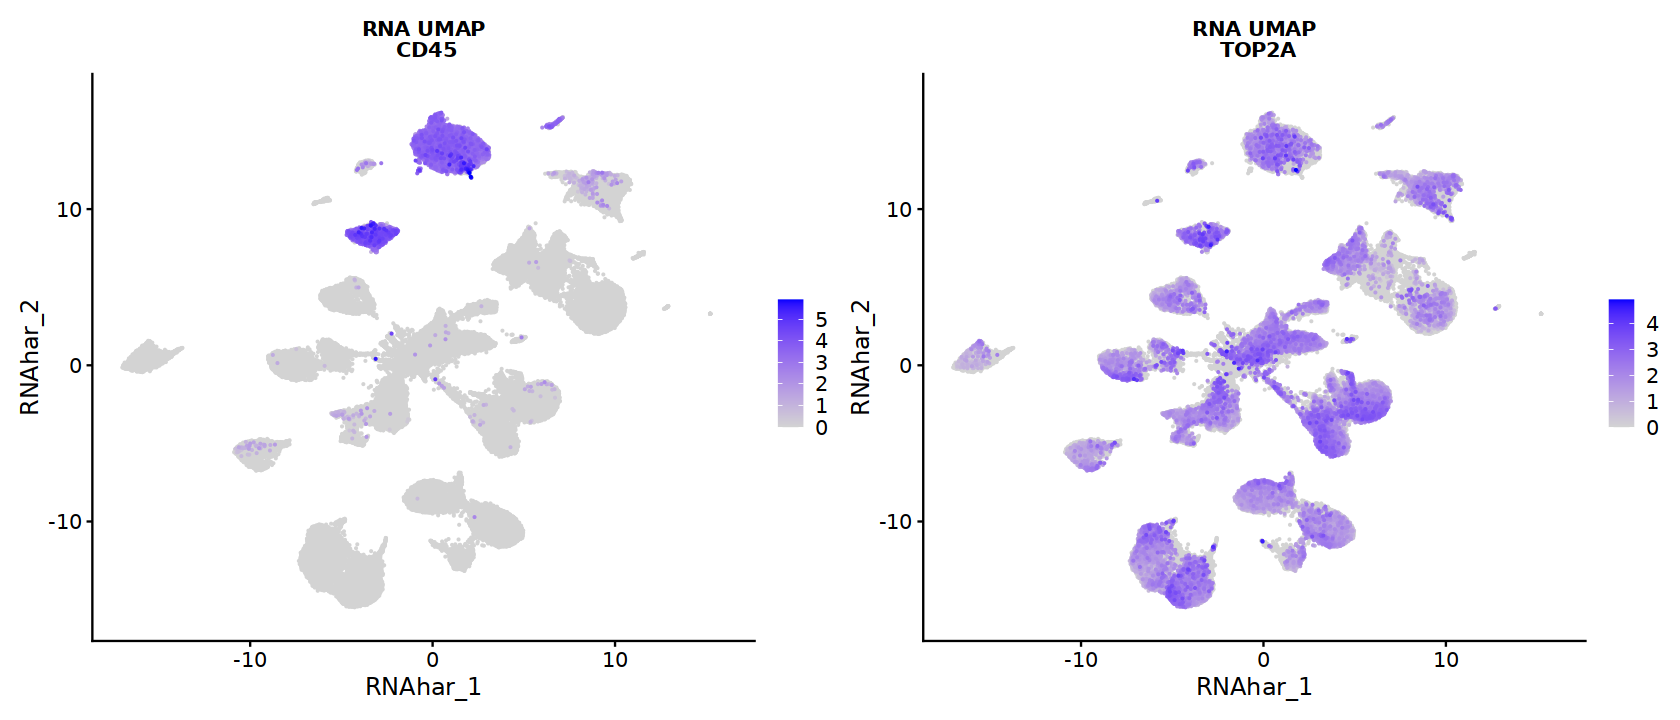

In [48]:
options(repr.plot.width = 14, repr.plot.height = 6)
patchwork::wrap_plots(list(p4,p5), ncol=2)

### ATAC

In [49]:
# make a copy of the reduction
integrated_obj@reductions$lsi.common_filt <- integrated_obj@reductions$lsi.common

# Filter to the desired number of components according to elbow
integrated_obj@reductions$lsi.common_filt@cell.embeddings <- integrated_obj@reductions$lsi.common_filt@cell.embeddings[, atac_comp]

integrated_obj@reductions$lsi.common_filt@feature.loadings <- integrated_obj@reductions$lsi.common_filt@feature.loadings[, atac_comp]

In [50]:
DefaultAssay(integrated_obj) <- "ATAC_unified"
integrated_obj <- RunHarmony(
  object = integrated_obj,
  group.by.vars = c("patient"),
  reduction = "lsi.common_filt",
  assay.use = "ATAC_unified",
  project.dim = F,
  max_iter = 15,
  reduction.save = "harmony_lsi.common"
)

Transposing data matrix

Warning message:
“Quick-TRANSfer stage steps exceeded maximum (= 5108550)”
Harmony 1/15

Harmony 2/15

Harmony converged after 2 iterations



In [51]:
integrated_obj <- RunUMAP(
  integrated_obj,
  dims = 1:19,
  reduction = "harmony_lsi.common",
  reduction.name = "umap.atac.harmony",
  reduction.key = "ATAChar_",
  assay = "ATAC_unified")

14:19:43 UMAP embedding parameters a = 0.9922 b = 1.112

14:19:43 Read 102171 rows and found 19 numeric columns

14:19:43 Using Annoy for neighbor search, n_neighbors = 30

14:19:43 Building Annoy index with metric = cosine, n_trees = 50

0%   10   20   30   40   50   60   70   80   90   100%

[----|----|----|----|----|----|----|----|----|----|

*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
|

14:19:54 Writing NN index file to temp file /scratch_tmp/53625861/RtmpxpwnoJ/file2f99e2199a8d1

14:19:54 Searching Annoy index using 1 thread, search_k = 3000

14:20:45 Annoy recall = 100%

14:20:47 Commencing smooth kNN distance calibration using 1 thread
 with target n_neighbors = 30

14:20:52 Initializing from normalized Laplacian + noise (using irlba)

14:20:56 Commencing optimization for 200 epochs, with 4457130 positive edges

14:22:57 Optimization finished



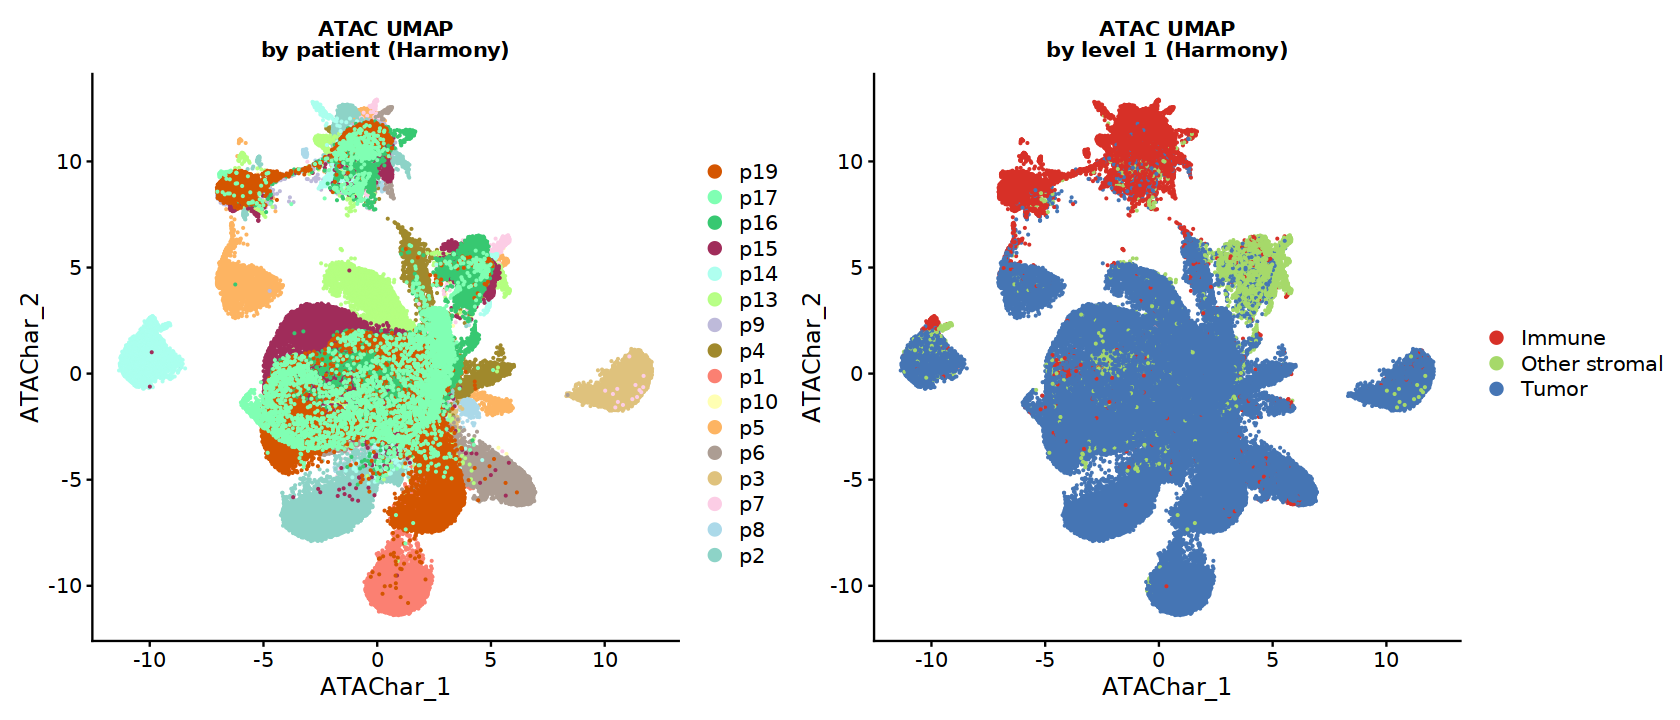

In [52]:
options(repr.plot.width = 14, repr.plot.height = 6)
p1 <- DimPlot(
  integrated_obj,
   reduction = "umap.atac.harmony",
   group.by = "patient",
   cols= colors_patients,
   pt.size = 0.1,
   raster=FALSE
) + ggtitle('ATAC UMAP\nby patient (Harmony)') + 
    theme(plot.title = element_text(hjust = 0.5, size = 12, face = "bold")) 

p2 <- DimPlot(
  integrated_obj,
   reduction = "umap.atac.harmony",
   group.by = "cell_groups",
   pt.size = 0.1,
   cols=colors_cellg,
   raster=FALSE
) + ggtitle('ATAC UMAP\nby level 1 (Harmony)') + 
    theme(plot.title = element_text(hjust = 0.5, size = 12, face = "bold"))

patchwork::wrap_plots(list(p1,p2), ncol=2)

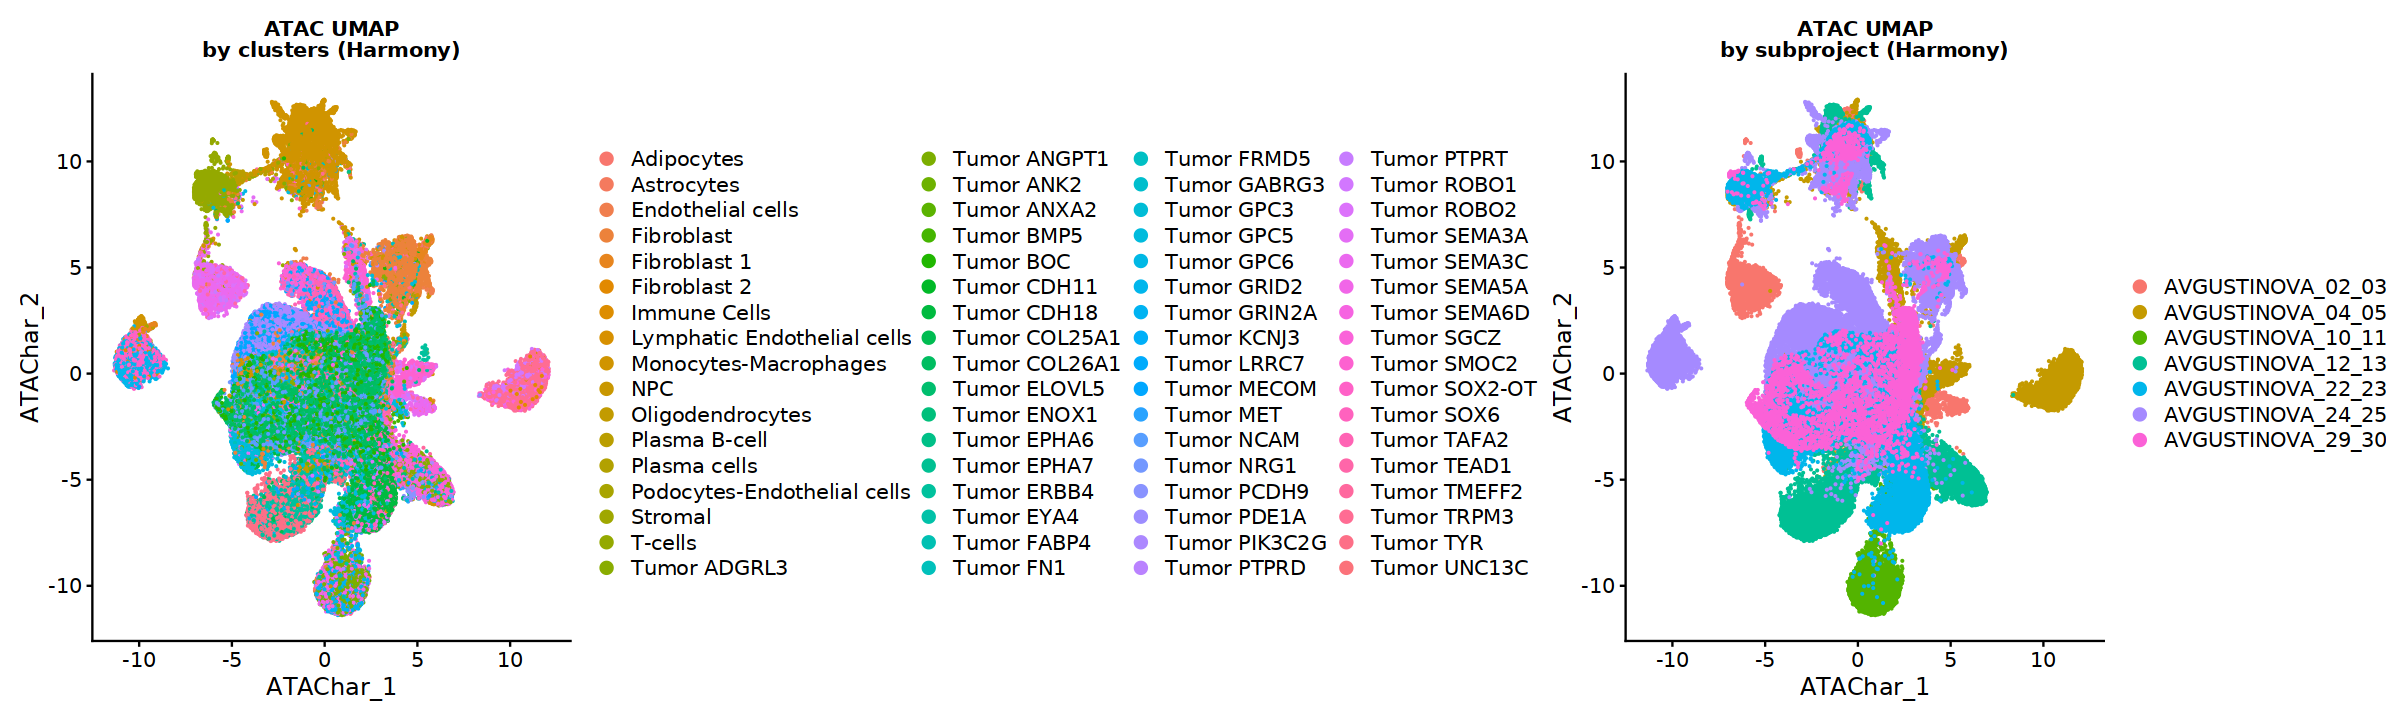

In [53]:
options(repr.plot.width = 20, repr.plot.height = 6)
p1 <- DimPlot(
  integrated_obj,
   reduction = "umap.atac.harmony",
   group.by = "clusters_donor",
   pt.size = 0.1,
   raster=FALSE
) + ggtitle('ATAC UMAP\nby clusters (Harmony)') + 
    theme(plot.title = element_text(hjust = 0.5, size = 12, face = "bold"))

p2 <- DimPlot(
  integrated_obj,
   reduction = "umap.atac.harmony",
   group.by = "subproj",
   pt.size = 0.1,
   raster=FALSE
) + ggtitle('ATAC UMAP\nby subproject (Harmony)') + 
    theme(plot.title = element_text(hjust = 0.5, size = 12, face = "bold"))

patchwork::wrap_plots(list(p1,p2), ncol=2)

In [54]:
p4 <- FeaturePlot(
  integrated_obj,
   reduction = "umap.atac.harmony",
   features = "PTPRC",
   pt.size = 0.1,
   order = T,
   raster=FALSE
) + ggtitle('ATAC UMAP\n CD45') + 
    theme(plot.title = element_text(hjust = 0.5, size = 12, face = "bold")) 

p5 <- FeaturePlot(
  integrated_obj,
   reduction = "umap.atac.harmony",
   features = "TOP2A",
   pt.size = 0.1,
   order = T,
   raster=FALSE
) + ggtitle('ATAC UMAP\n TOP2A') + 
    theme(plot.title = element_text(hjust = 0.5, size = 12, face = "bold")) 

Warning message:
“Could not find PTPRC in the default search locations, found in RNA assay instead”
Warning message:
“Could not find TOP2A in the default search locations, found in RNA assay instead”


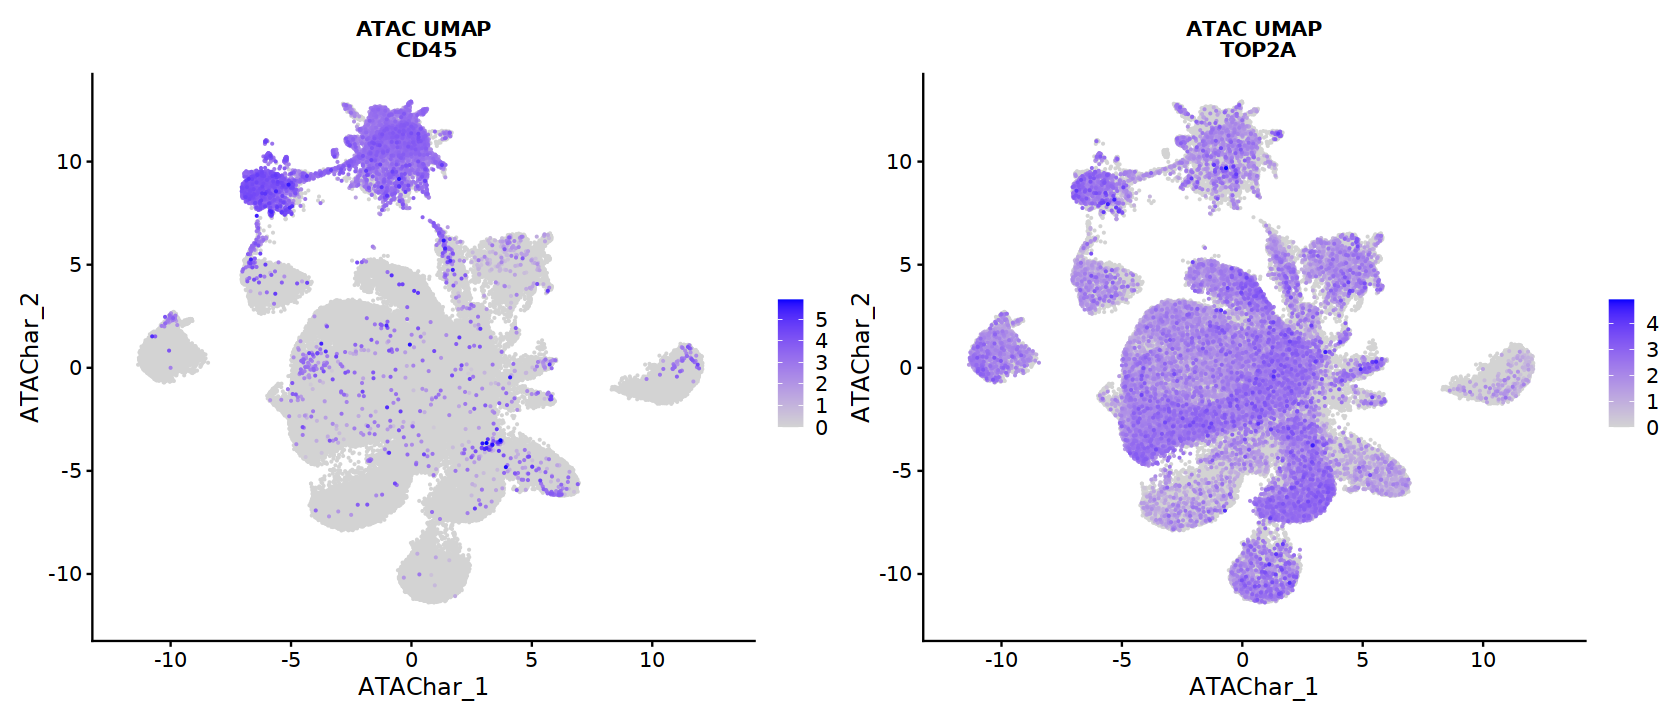

In [55]:
options(repr.plot.width = 14, repr.plot.height = 6)
patchwork::wrap_plots(list(p4,p5), ncol=2)

In [56]:
integrated_obj[["pca"]] <- NULL
integrated_obj[["pca_filt"]] <- NULL
integrated_obj[["lsi.common"]] <- NULL
integrated_obj[["lsi.common_filt"]] <- NULL
integrated_obj[["umap.atac.harmony"]] <- NULL
#integrated_obj[["umap.rna.harmony"]] <- NULL

### Joint 

In [57]:
integrated_obj <- FindMultiModalNeighbors(
 integrated_obj,
 reduction.list = list("harmony_pca", "harmony_lsi.common"),
 dims.list = list(rna_comp, 1:19)
)
integrated_obj <- RunUMAP(
   integrated_obj,
   return.model=T,
   project.dim = T,
   nn.name = "weighted.nn",
   reduction.name = "wnn.umap",
   reduction.key = "wnnUMAP_"
)

Calculating cell-specific modality weights

Finding 20 nearest neighbors for each modality.

Calculating kernel bandwidths

Finding multimodal neighbors

Constructing multimodal KNN graph

Constructing multimodal SNN graph

Warning message:
“The following arguments are not used: project.dim”
UMAP will return its model

14:29:21 UMAP embedding parameters a = 0.9922 b = 1.112

14:29:22 Commencing smooth kNN distance calibration using 1 thread
 with target n_neighbors = 20

14:29:25 Initializing from normalized Laplacian + noise (using irlba)

14:29:28 Commencing optimization for 200 epochs, with 3402272 positive edges

14:31:49 Optimization finished

14:31:49 Note: model requested with precomputed neighbors. For transforming new data, distance data must be provided separately



In [58]:
custom_order <- c('p2','p8','p14','p17','p13','p9','p7','p6','p15','p10','p16','p3','p5','p1','p4','p19')
integrated_obj$patient <- factor(integrated_obj$patient, level=custom_order)

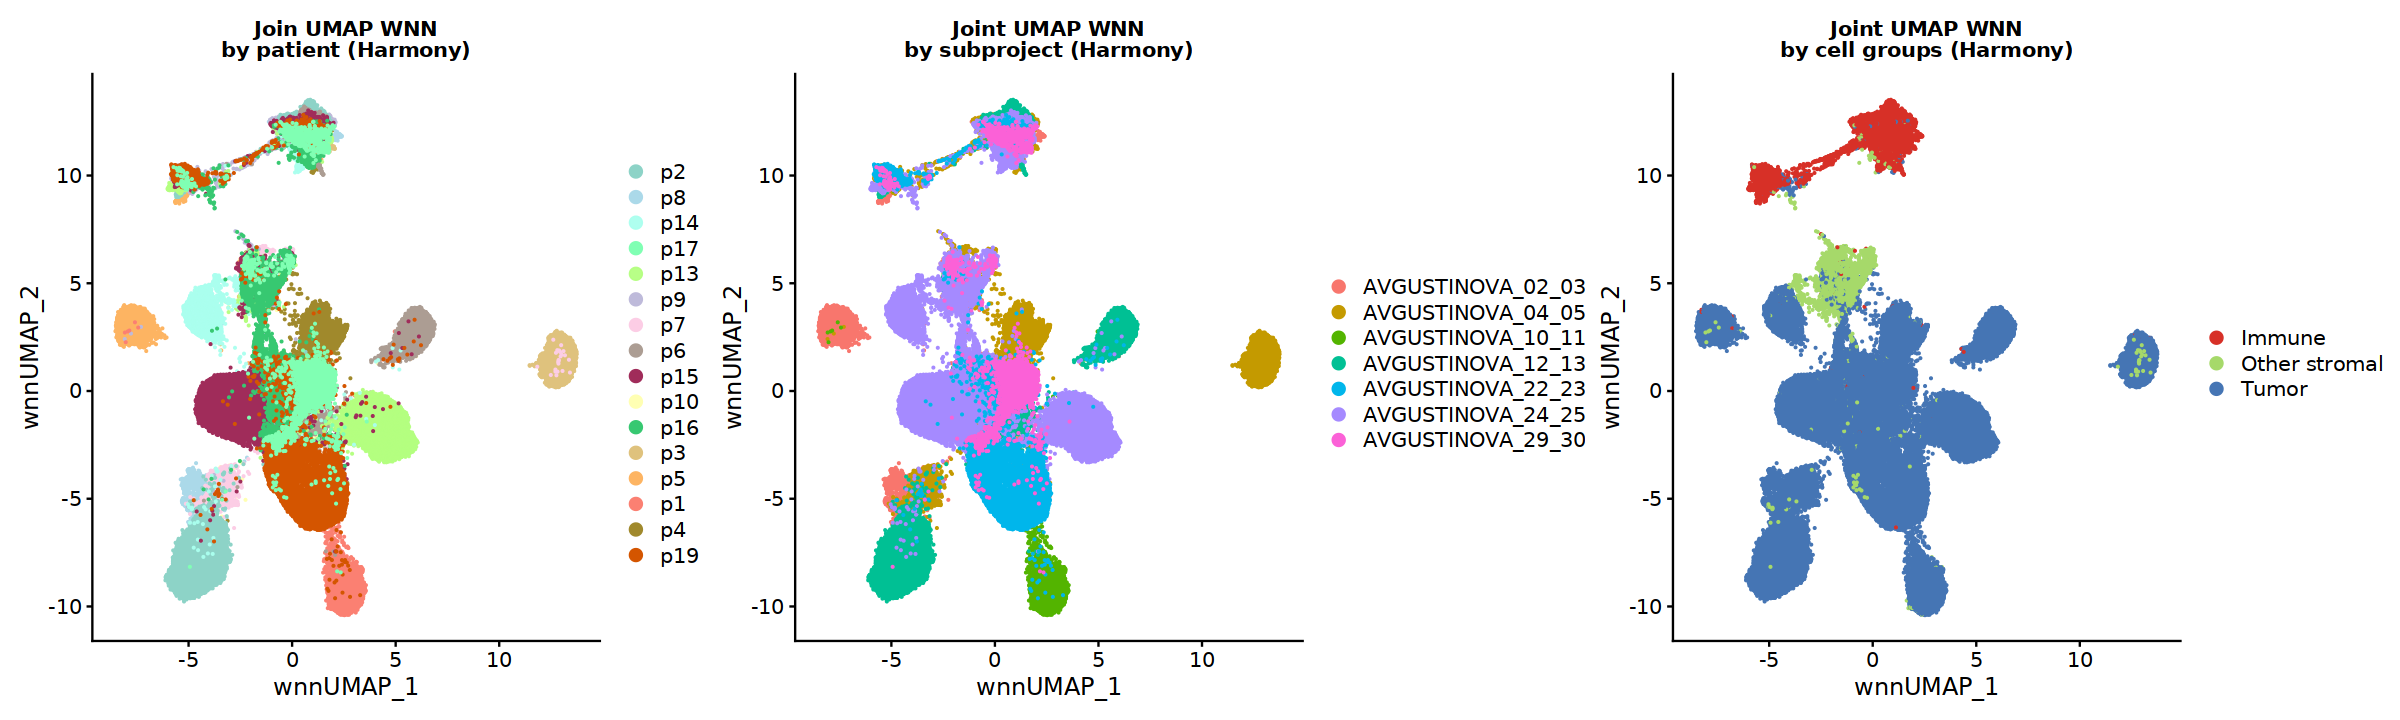

In [59]:
options(repr.plot.width = 20, repr.plot.height = 6)
p1 <- DimPlot(
  integrated_obj,
   reduction = "wnn.umap",
   group.by = "patient",
   pt.size = 0.1,
   cols = colors_patients,
   raster=FALSE
) + ggtitle('Join UMAP WNN\nby patient (Harmony)') + 
    theme(plot.title = element_text(hjust = 0.5, size = 12, face = "bold")) 

p2 <- DimPlot(
  integrated_obj,
   reduction = "wnn.umap",
   group.by = "subproj",
   pt.size = 0.1,
   raster=FALSE
) + ggtitle('Joint UMAP WNN\nby subproject (Harmony)') + 
    theme(plot.title = element_text(hjust = 0.5, size = 12, face = "bold"))

p3 <- DimPlot(
  integrated_obj,
   reduction = "wnn.umap",
   group.by = "cell_groups",
   pt.size = 0.1,
   cols=colors_cellg,
   raster=FALSE
) + ggtitle('Joint UMAP WNN\nby cell groups (Harmony)') + 
    theme(plot.title = element_text(hjust = 0.5, size = 12, face = "bold"))

patchwork::wrap_plots(list(p1,p2,p3), ncol=3)

In [60]:
options(repr.plot.width = 14, repr.plot.height = 6)
jp <- patchwork::wrap_plots(list(p1,p3), ncol=2)

In [61]:
ggsave(plot = p1, width = 7, height = 6, dpi = 300, 
       file = here::here(glue::glue("{int}/{plt_dir}/4.0.5-UMAP_integr_pat.svg")))
ggsave(plot = p3, width = 7, height = 6, dpi = 300, 
       file = here::here(glue::glue("{int}/{plt_dir}/4.0.5-UMAP_integr_l1.svg")))
ggsave(plot = jp, width = 14, height = 6, dpi = 300, 
       file = here::here(glue::glue("{int}/{plt_dir}/4.0.5-UMAP_integr_both.svg")))

In [62]:
DefaultAssay(integrated_obj) <- "RNA"
saveRDS(integrated_obj, here(glue("{int}/{robj_dir}/4.0.5-integrated_filt.rds")))

In [63]:
integrated_obj

An object of class Seurat 
222285 features across 102171 samples within 2 assays 
Active assay: RNA (33555 features, 5605 variable features)
 1 other assay present: ATAC_unified
 4 dimensional reductions calculated: wnn.umap, harmony_pca, umap.rna.harmony, harmony_lsi.common

## Session

In [64]:
sessionInfo()

R version 4.1.1 (2021-08-10)
Platform: x86_64-conda-linux-gnu (64-bit)
Running under: CentOS Linux 7 (Core)

Matrix products: default
BLAS/LAPACK: /home/groups/singlecell/isentis/conda_envs/ines_r4.1.1c/lib/libopenblasp-r0.3.24.so

locale:
 [1] LC_CTYPE=es_ES.UTF-8       LC_NUMERIC=C              
 [3] LC_TIME=es_ES.UTF-8        LC_COLLATE=es_ES.UTF-8    
 [5] LC_MONETARY=es_ES.UTF-8    LC_MESSAGES=es_ES.UTF-8   
 [7] LC_PAPER=es_ES.UTF-8       LC_NAME=C                 
 [9] LC_ADDRESS=C               LC_TELEPHONE=C            
[11] LC_MEASUREMENT=es_ES.UTF-8 LC_IDENTIFICATION=C       

attached base packages:
[1] stats4    stats     graphics  grDevices utils     datasets  methods  
[8] base     

other attached packages:
 [1] glue_1.6.2                  here_1.0.1                 
 [3] harmony_1.0.3               Rcpp_1.0.10                
 [5] scran_1.22.1                scater_1.22.0              
 [7] scuttle_1.4.0               SingleCellExperiment_1.16.0
 [9] SummarizedExperime